<a href="https://colab.research.google.com/github/butthamza20/ECS708U-P-Fashion-MNIST-Coursework/blob/main/ECS708U_P_Fashion_MNIST_Coursework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ECS708U Fashion-MNIST Coursework

**Repository:** https://github.com/butthamza20/ECS708U-P-Fashion-MNIST-Coursework

# Part 0: Data

## 0.1 Fixed data partitions

### Importing libraries

In [56]:
# Standard library
import os
import sys
import time
import random

# Numerical and plotting libraries
import numpy as np
import matplotlib.pyplot as plt

# PyTorch: loading Fashion-MNIST and building DataLoaders
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader, TensorDataset
import torch.nn as nn
import copy


# scikit-learn: splitting, scaling, models and metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

### Setup: random seeds and hardware

In [2]:
# One seed for the whole notebook
SEED = 42

# Seed every random number generator used below
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Record the software versions and hardware for reproducibility
print("Python version:     ", sys.version.split()[0])
print("PyTorch version:    ", torch.__version__)
print("Torchvision version:", torchvision.__version__)

if torch.cuda.is_available():
    print("Device: GPU -", torch.cuda.get_device_name(0))
else:
    print("Device: CPU (no GPU available)")

# Device for any later PyTorch training (GPU if available, otherwise CPU)
device = "cuda" if torch.cuda.is_available() else "cpu"

Python version:      3.13.18
PyTorch version:     2.14.1+cpu
Torchvision version: 0.29.1+cpu
Device: CPU (no GPU available)


### Loading the Fashion MNIST training dataset

In [3]:
train_data = datasets.FashionMNIST(root='data', train=True, download=True, transform=transforms.ToTensor())

train_data_length = len(train_data)
print("\nTraining images:", train_data_length)
print("Classes:", train_data.classes)

100%|██████████| 26.4M/26.4M [00:01<00:00, 15.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 268kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.04MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.4MB/s]


Training images: 60000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## Loading the Testing Dataset

In [4]:
test_data = datasets.FashionMNIST(root='data', train=False, download=True, transform=transforms.ToTensor())

test_data_length = len(test_data)
print("\nTest images:", test_data_length)
print("Classes:", test_data.classes)


Test images: 10000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### Viewing example training images

Example positions: [41905, 7296, 1639, 48598, 18024, 16049]


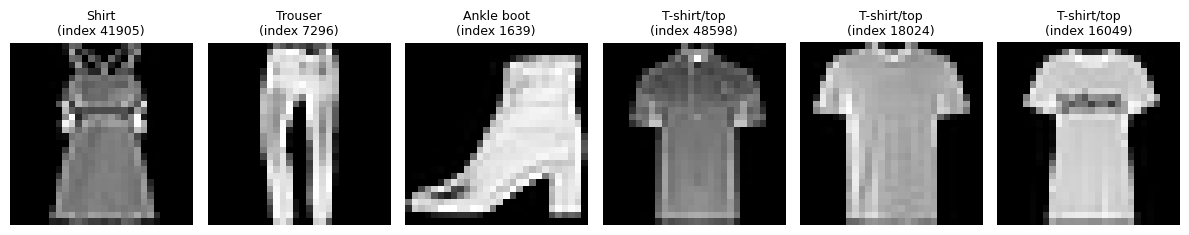

In [5]:
# A separate random generator for this cell only, so re-running it always shows the same images
example_rng = random.Random(SEED)

# Pick 6 different positions from 0 to 59,999 (sample never goes out of range or repeats)
example_positions = example_rng.sample(range(train_data_length), 6)
print("Example positions:", example_positions)

fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))

for i, position in enumerate(example_positions):
    image, label = train_data[position]
    # squeeze() removes the colour-channel dimension: [1, 28, 28] -> [28, 28]
    axes[i].imshow(image.squeeze(), cmap='gray', interpolation='nearest')
    axes[i].set_title(f"{train_data.classes[label]}\n(index {position})", fontsize=9)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### Creating the train/validation split (training set only)

In [6]:
# Positions 0..59,999 and the label of every training image
all_indices = list(range(train_data_length))
all_labels = train_data.targets

# Stratified split: 10,000 positions go to validation, the remaining 50,000 to training
train_indices, val_indices = train_test_split(
    all_indices,
    test_size=10000,         # size of the second group (validation, not the real test set)
    stratify=all_labels,     # keep the same class balance in both groups
    random_state=SEED,       # same split on every run
)

# Subsets only store which positions to use; no images are copied
train_set = Subset(train_data, train_indices)
val_set = Subset(train_data, val_indices)

### Checking the split

In [7]:
# Positions that appear in both sets (should be none)
overlap = set(train_indices) & set(val_indices)

print("Train size:            ", len(train_set))
print("Validation size:       ", len(val_set))
print("Images in both sets:   ", len(overlap))
# bincount counts how many images there are of each label 0-9
print("Train class counts:    ", torch.bincount(all_labels[train_indices]).tolist())
print("Validation class counts:", torch.bincount(all_labels[val_indices]).tolist())

Train size:             50000
Validation size:        10000
Images in both sets:    0
Train class counts:     [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]
Validation class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


The output confirms that the split worked as intended: **50,000** training and **10,000** validation images,
**5,000** and **1,000** images of each of the 10 classes, and **no image in both sets**.

### Saving the split indices

In [8]:
os.makedirs("splits", exist_ok=True)

np.save("splits/train_indices.npy", np.array(train_indices))
np.save("splits/val_indices.npy", np.array(val_indices))

#### Clustering training subset (3,000)

In [9]:
cluster_train_indices, _ = train_test_split(
    train_indices,
    train_size=3000,
    stratify=all_labels[train_indices],
    random_state=SEED,
)

#### Clustering validation subset (1,000)

In [10]:
cluster_val_indices, _ = train_test_split(
    val_indices,
    train_size=1000,
    stratify=all_labels[val_indices],
    random_state=SEED,
)

#### Clustering test subset (1,000)

In [11]:
all_test_indices = list(range(test_data_length))

cluster_test_indices, _ = train_test_split(
    all_test_indices,
    train_size=1000,
    stratify=test_data.targets,
    random_state=SEED,
)

#### Checking the clustering subsets

In [12]:
# Sizes
print("Clustering train size:     ", len(cluster_train_indices))
print("Clustering validation size:", len(cluster_val_indices))
print("Clustering test size:      ", len(cluster_test_indices))

# Images per class in each subset
print("Clustering train per class:     ", torch.bincount(all_labels[cluster_train_indices]).tolist())
print("Clustering validation per class:", torch.bincount(all_labels[cluster_val_indices]).tolist())
print("Clustering test per class:      ", torch.bincount(test_data.targets[cluster_test_indices]).tolist())

# Each subset comes from the right partition (<= means "is contained in"), and train/val do not overlap
print("Clustering train all from training partition:  ", set(cluster_train_indices) <= set(train_indices))
print("Clustering validation all from validation split:", set(cluster_val_indices) <= set(val_indices))
print("Overlap between clustering train and validation:", len(set(cluster_train_indices) & set(cluster_val_indices)))

Clustering train size:      3000
Clustering validation size: 1000
Clustering test size:       1000
Clustering train per class:      [300, 300, 300, 300, 300, 300, 300, 300, 300, 300]
Clustering validation per class: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Clustering test per class:       [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Clustering train all from training partition:   True
Clustering validation all from validation split: True
Overlap between clustering train and validation: 0


The output confirms sizes of **3,000 / 1,000 / 1,000**, exactly **300 / 100 / 100 images per class**, that
the clustering train and validation subsets come from the correct partitions (**True / True**), and that
they share **no images**.

#### Saving the clustering subset indices

In [13]:
# Save the three clustering subsets next to the train/validation split
np.save("splits/cluster_train_indices.npy", np.array(cluster_train_indices))
np.save("splits/cluster_val_indices.npy", np.array(cluster_val_indices))
np.save("splits/cluster_test_indices.npy", np.array(cluster_test_indices))

### DataLoaders

In [14]:
size_of_batch = 64

# Seeded random generator for the training shuffle (_ = stops it printing an object description)
g = torch.Generator()
_ = g.manual_seed(SEED)

train_loader = DataLoader(train_set, batch_size=size_of_batch, shuffle=True, generator=g)
val_loader = DataLoader(val_set, batch_size=size_of_batch, shuffle=False)
test_loader = DataLoader(test_data, batch_size=size_of_batch, shuffle=False)

### Checking the DataLoaders

In [15]:
# Take one batch to check its shape
temp_images, temp_labels = next(iter(train_loader))

# Reset the generator so this check does not change the training shuffle later
_ = g.manual_seed(SEED)

print("One batch of images:", tuple(temp_images.shape))
print("One batch of labels:", tuple(temp_labels.shape))
print("Train batches:      ", len(train_loader))
print("Validation batches: ", len(val_loader))
print("Test batches:       ", len(test_loader))

One batch of images: (64, 1, 28, 28)
One batch of labels: (64,)
Train batches:       782
Validation batches:  157
Test batches:        157


Each batch holds 64 greyscale 28 × 28 images and their 64 labels. 50,000 / 64 = 781.25, so there are
781 full training batches plus one smaller batch of 16 images, giving **782**. Validation and test each
have **157** batches (156 full batches plus one of 16).

Taking a batch uses up some of the generator's randomness, so the generator is reset straight after the
check. Without the reset, the later training order would depend on whether this cell had been run
(hidden state).

# Part 1: Classical classification

**Guiding question:** how do different classifiers use the same data, and what can their errors tell us?

**Order of work.** The sections keep the brief's numbering, but the complexity study (1.4) is run
**before** the metrics (1.2) and the error analysis (1.3). This way, 1.2 and 1.3 report the settings that
were **selected on validation** in 1.4, rather than untuned baselines. Everything in Part 1 uses the
**validation set only**; the test set is not used.

## 1.1 Models

### Choice of models

Two classifiers taught in the module are compared: **logistic regression** and **k-nearest neighbours (kNN)**.

| | Logistic regression | k-nearest neighbours |
|---|---|---|
| **How it predicts** | Learns one weight per pixel for each class, adds up weight × pixel value for each class, and picks the class with the highest score (turned into probabilities with the softmax function). | Finds the *k* training images closest to the new image (Euclidean distance) and takes a majority vote of their labels. |
| **How it is fitted** | Optimisation (the L-BFGS algorithm): it adjusts the weights to minimise the cross-entropy loss plus an L2 penalty on the weights. | Not really fitted: it stores all the training images. |
| **How complexity is controlled** | `C`, the inverse of the regularisation strength. Small C means a strong penalty and a simpler model; large C means a more complex model. | `k`, the number of neighbours. Small k (e.g. 1) means a very complex model that memorises the training data; large k means a smoother, simpler model. |
| **Type** | Linear, parametric | Non-linear, instance-based |

### Why these two suit this data

- **They use the pixels in completely different ways.** Logistic regression learns a single linear
  "template" of weights per class, while kNN compares each image with stored examples. Comparing their
  errors (1.3) therefore says something about the data, not just about one method.
- **Fashion-MNIST is a good fit for both.** The images are small (784 pixels), centred and aligned, so the
  same pixel position means roughly the same part of the garment in every image. That makes both pixel
  weights and pixel distances meaningful.
- **Each has one clear complexity setting** (C and k), which suits the complexity study (1.4).
- **Logistic regression gives real probabilities**, which the threshold study (1.5) needs. kNN's scores are
  vote fractions, not probabilities.
- **They are quick enough to tune on a CPU** and easy to explain.

They are not the most accurate possible models for this data: convolutional neural networks, which use the
2D structure of the images, usually do better. The aim of Part 1 is to compare classical classifiers.

### Preparing the data for scikit-learn

scikit-learn needs plain tables of numbers rather than tensors: one **row per image** and one **column per
pixel**. Each 28 × 28 image is flattened into a row of 784 values and scaled to 0–1, using the saved
training and validation positions. The test set is not prepared here.

In [16]:
# Flatten each 28x28 image into one row of 784 pixels, scaled to 0-1
X_train = train_data.data[train_indices].reshape(-1, 784).numpy() / 255.0
y_train = train_data.targets[train_indices].numpy()

X_val = train_data.data[val_indices].reshape(-1, 784).numpy() / 255.0
y_val = train_data.targets[val_indices].numpy()

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:  ", X_val.shape, " y_val:  ", y_val.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())

X_train: (50000, 784)  y_train: (50000,)
X_val:   (10000, 784)  y_val:   (10000,)
Pixel range: 0.0 to 1.0


The output confirms 50,000 training rows and 10,000 validation rows, each with 784 pixels between 0 and 1.

### Logistic regression: baseline

Pixels are standardised (mean 0, standard deviation 1 per pixel) with a `StandardScaler` that is **fitted on
the 50,000 training images only** and then applied to the validation images (R2). Standardising puts every
pixel on the same scale, which helps the optimiser converge.

The baseline uses the default **C = 1.0** with up to **1,000 iterations**, because the default of 100 is not
enough for this data and would give a convergence warning.

In [17]:
# Standardise each pixel using statistics from the TRAINING data only (R2)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learns mean and std from training data
X_val_scaled = scaler.transform(X_val)           # reuses the training mean and std

print("Train mean (approx 0):", round(X_train_scaled.mean(), 4))
print("Train std  (approx 1):", round(X_train_scaled.std(), 4))

Train mean (approx 0): 0.0
Train std  (approx 1): 1.0


In [18]:
# Baseline: default regularisation (C = 1.0), enough iterations to converge
log_reg = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)

# Time the fit, because runtimes are part of the record
start = time.time()
log_reg.fit(X_train_scaled, y_train)
log_reg_fit_time = time.time() - start

print(f"Logistic regression training time: {log_reg_fit_time:.1f} seconds")
# If this equals max_iter, the optimiser stopped before converging
print("Iterations used:", log_reg.n_iter_)

Logistic regression training time: 320.4 seconds
Iterations used: [883]


In [19]:
# Accuracy on the images it was trained on, and on the unseen validation images
log_reg_train_acc = accuracy_score(y_train, log_reg.predict(X_train_scaled))
log_reg_val_acc = accuracy_score(y_val, log_reg.predict(X_val_scaled))

print(f"Training accuracy:   {log_reg_train_acc:.4f}")
print(f"Validation accuracy: {log_reg_val_acc:.4f}")
# A large gap would mean overfitting
print(f"Gap (train - val):   {log_reg_train_acc - log_reg_val_acc:.4f}")

Training accuracy:   0.8879
Validation accuracy: 0.8548
Gap (train - val):   0.0331


The baseline logistic regression **converged in 883 of 1,000 iterations** and took **356.6 seconds** on the CPU.
It reached **88.79%** training accuracy and **85.48%** validation accuracy. The gap of **3.3 percentage points**
suggests only mild overfitting at this regularisation strength.

### kNN: baseline

kNN uses the **0–1 pixels, not the standardised ones**. Standardising divides each pixel by its spread; the
border pixels are almost always black, so their spread is tiny, and dividing by it would magnify small noise
in them. kNN would then treat that noise as important when measuring distances. Logistic regression does not
have this problem because it learns how much weight each pixel gets. This preprocessing difference between the
two models is deliberate and stated here (R4).

The baseline uses **k = 5**. Because kNN is slow to predict, its training accuracy is estimated on a **fixed,
seeded sample of 5,000 training images**; the same sample is reused in 1.4.

In [20]:
# Baseline kNN with k = 5; n_jobs=-1 uses all CPU cores for prediction
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

# "Fitting" kNN just stores the training images, so it is almost instant
start = time.time()
knn.fit(X_train, y_train)          # 0-1 pixels, not scaled
knn_fit_time = time.time() - start

print(f"kNN fit time: {knn_fit_time:.2f} seconds")

kNN fit time: 0.07 seconds


In [21]:
# Prediction is the slow part: every validation image is compared with all 50,000 training images
start = time.time()
knn_val_pred = knn.predict(X_val)
knn_pred_time = time.time() - start

knn_val_acc = accuracy_score(y_val, knn_val_pred)
print(f"kNN prediction time (10,000 images): {knn_pred_time:.1f} seconds")
print(f"kNN validation accuracy: {knn_val_acc:.4f}")

kNN prediction time (10,000 images): 30.6 seconds
kNN validation accuracy: 0.8595


In [22]:
# A fixed, seeded sample of 5,000 training rows (row numbers in X_train), reused in 1.4
sample_rng = np.random.default_rng(SEED)
train_sample = sample_rng.choice(len(X_train), size=5000, replace=False)

knn_train_acc = accuracy_score(y_train[train_sample], knn.predict(X_train[train_sample]))
print(f"kNN training accuracy (5,000-image sample): {knn_train_acc:.4f}")
print(f"Gap (train - val): {knn_train_acc - knn_val_acc:.4f}")

kNN training accuracy (5,000-image sample): 0.8978
Gap (train - val): 0.0383


The baseline kNN "fitted" in **0.12 seconds** but took **45.6 seconds** to predict the 10,000 validation images.
It reached **85.95%** validation accuracy and **89.78%** training accuracy (on the 5,000-image sample), a gap of
**3.8 points**.

**Baseline comparison**

| | Logistic regression (C = 1) | kNN (k = 5) |
|---|---|---|
| Validation accuracy | 85.48% | 85.95% |
| Train − val gap | 3.3 points | 3.8 points |
| Fit time | 356.6 s | 0.12 s |
| Prediction time (10,000 images) | fast | 45.6 s |

The two baselines are close in accuracy (0.47 points, about 47 images, from one split and one seed), so
neither is clearly better at default settings. They spend their time in opposite places: logistic regression
is slow to fit and fast to predict, while kNN is instant to fit and slow to predict. This follows directly
from how each one works.

## 1.4 Complexity study

*(Run before 1.2 and 1.3, so those sections use the settings selected here.)*

Each model's complexity setting is varied, and **training and validation accuracy** are compared. The setting
with the **highest validation accuracy** is selected (R1). All settings of a model use the same training data,
validation set and preprocessing (R4).

### kNN: varying k

Eight values of k are tried, from very complex (k = 1) to quite simple (k = 51). Odd values make tied votes
less likely. Training accuracy uses the same 5,000-image training sample for every k.

In [23]:
k_values = [1, 3, 5, 7, 11, 15, 25, 51]

knn_results = []   # one entry per k

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    model.fit(X_train, y_train)

    # Time the two prediction steps (validation + training sample)
    start = time.time()
    val_acc = accuracy_score(y_val, model.predict(X_val))
    train_acc = accuracy_score(y_train[train_sample], model.predict(X_train[train_sample]))
    elapsed = time.time() - start

    knn_results.append({"k": k, "train_acc": train_acc, "val_acc": val_acc, "time_s": elapsed})
    # {k:>2} pads the number to 2 characters so the columns line up
    print(f"k = {k:>2}:  train {train_acc:.4f}   val {val_acc:.4f}   gap {train_acc - val_acc:.4f}   ({elapsed:.0f} s)")

k =  1:  train 1.0000   val 0.8502   gap 0.1498   (47 s)
k =  3:  train 0.9206   val 0.8579   gap 0.0627   (46 s)
k =  5:  train 0.8978   val 0.8595   gap 0.0383   (46 s)
k =  7:  train 0.8888   val 0.8617   gap 0.0271   (46 s)
k = 11:  train 0.8732   val 0.8538   gap 0.0194   (46 s)
k = 15:  train 0.8650   val 0.8513   gap 0.0137   (47 s)
k = 25:  train 0.8534   val 0.8467   gap 0.0067   (46 s)
k = 51:  train 0.8358   val 0.8366   gap -0.0008   (48 s)


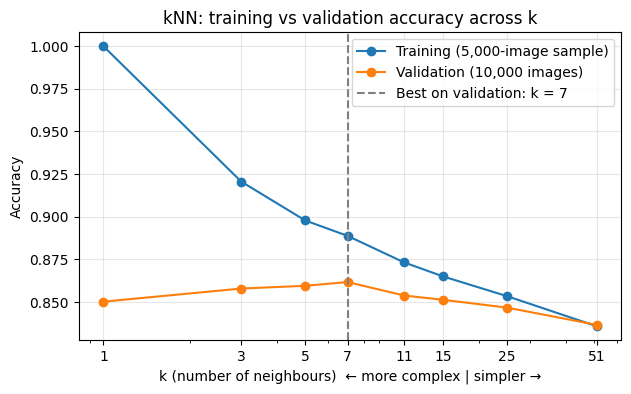

Best k on validation: 7 (validation accuracy 0.8617)


In [24]:
# Pull each column out of the results
ks = [r["k"] for r in knn_results]
train_accs = [r["train_acc"] for r in knn_results]
val_accs = [r["val_acc"] for r in knn_results]

# Best k is chosen by code (highest validation accuracy), not typed in by hand
best = max(knn_results, key=lambda r: r["val_acc"])

plt.figure(figsize=(7, 4))
plt.plot(ks, train_accs, marker="o", label="Training (5,000-image sample)")
plt.plot(ks, val_accs, marker="o", label="Validation (10,000 images)")
plt.axvline(best["k"], linestyle="--", color="gray", label=f"Best on validation: k = {best['k']}")

# Log scale spreads out the small values of k
plt.xscale("log")
plt.xticks(ks, ks)
plt.xlabel("k (number of neighbours)  ← more complex | simpler →")
plt.ylabel("Accuracy")
plt.title("kNN: training vs validation accuracy across k")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Best k on validation: {best['k']} (validation accuracy {best['val_acc']:.4f})")

**Interpretation.**

- **k = 1** gives **100%** training accuracy, because each training image's nearest neighbour is itself, but the
  lowest validation accuracy of the small k values (**85.02%**). The gap of **15 points** is clear overfitting:
  the model memorises the training set, including its noise.
- **From k = 3 to k = 7**, training accuracy falls while validation accuracy **rises**, because averaging over
  more neighbours smooths out noise. **k = 7** gives the **best validation accuracy (86.17%)**.
- **From k = 11 to k = 51**, both accuracies fall. The model becomes too simple: with 51 neighbours, votes are
  pulled towards whichever classes are common in that region of pixel space (underfitting).
- At **k = 51** the gap is −0.08 points, which is essentially zero; the small negative value is noise from
  estimating training accuracy on a 5,000-image sample.

For kNN, **small k means a complex model and large k a simple one**. As k grows, the train−validation gap shrinks
steadily from 15 points to about 0, but validation accuracy peaks in the middle. k = 5 (85.95%) and k = 7
(86.17%) differ by only 0.22 points, so the region k ≈ 5–7 performs similarly; **k = 7 is selected** by the rule
"highest validation accuracy". Each value of k took about **45 seconds** to evaluate.

### Logistic regression: varying C

Each fit on all 50,000 images took about 6 minutes on the CPU, so the C sweep uses a **seeded, stratified
10,000-image subset** of the training set (1,000 per class). Every value of C is fitted on the **same** subset
and scored on the **full** validation set. The selected C is then refitted on all 50,000 images.

The scaler was fitted on all 50,000 training images, which is still training data only, so there is no leakage.

**Index convention:** `lr_subset` holds **row numbers in `X_train`** (0–49,999), not positions in the original
60,000 images.

C values go up in factors of 10, from very strong regularisation (simple) to very weak (complex). Note that
this is the **opposite direction to kNN's k**: here, **large C means a more complex model**.

In [25]:
# Pick 10,000 of the 50,000 training rows, 1,000 per class
lr_subset, _ = train_test_split(
    np.arange(len(X_train)),   # row numbers in X_train
    train_size=10000,
    stratify=y_train,
    random_state=SEED,
)

X_sub = X_train_scaled[lr_subset]
y_sub = y_train[lr_subset]

print("Subset size:", len(lr_subset))
print("Per class:", np.bincount(y_sub).tolist())

Subset size: 10000
Per class: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


In [26]:
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
MAX_ITER = 1000

lr_results = []   # one entry per C

for C in C_values:
    model = LogisticRegression(C=C, max_iter=MAX_ITER, random_state=SEED)

    start = time.time()
    model.fit(X_sub, y_sub)
    elapsed = time.time() - start

    # Record whether the optimiser finished before hitting the iteration limit
    iters = int(model.n_iter_[0])
    converged = iters < MAX_ITER

    train_acc = accuracy_score(y_sub, model.predict(X_sub))          # the 10,000 images it was fitted on
    val_acc = accuracy_score(y_val, model.predict(X_val_scaled))     # the full validation set

    lr_results.append({"C": C, "train_acc": train_acc, "val_acc": val_acc,
                       "iters": iters, "converged": converged, "time_s": elapsed})
    print(f"C = {C:<7}  train {train_acc:.4f}   val {val_acc:.4f}   gap {train_acc - val_acc:.4f}   "
          f"iters {iters:>4} {'' if converged else '(NOT converged)'}   ({elapsed:.0f} s)")

C = 0.0001   train 0.7817   val 0.7856   gap -0.0039   iters   94    (10 s)
C = 0.001    train 0.8458   val 0.8375   gap 0.0083   iters  173    (21 s)
C = 0.01     train 0.8868   val 0.8518   gap 0.0350   iters  347    (41 s)
C = 0.1      train 0.9262   val 0.8370   gap 0.0892   iters  568    (67 s)
C = 1        train 0.9598   val 0.8083   gap 0.1515   iters  542    (62 s)
C = 10       train 0.9776   val 0.7851   gap 0.1925   iters  911    (105 s)
C = 100      train 0.9875   val 0.7725   gap 0.2150   iters 1000 (NOT converged)   (118 s)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Interpretation.** As C increases, training accuracy rises steadily from **78.2% to 98.8%**, but validation
accuracy peaks at **C = 0.01 (85.18%)** and then **falls** to 77.3%. The gap grows from about 0 to **21.5 points**.

- **C = 0.0001:** strong regularisation; training and validation are both low (about 78%) with no gap, so the
  model **underfits**.
- **C = 0.01:** the best balance on validation.
- **C ≥ 0.1:** weaker regularisation lets the weights fit details specific to the 10,000 training images that
  do not carry over to new images, so the model **overfits**.

C = 100 reached the 1,000-iteration limit and gave a **convergence warning**, which is resolved below.

#### Resolving the convergence warning (C = 100)

In [27]:
# Refit C = 100 with a higher iteration limit to check whether it converges
model = LogisticRegression(C=100, max_iter=3000, random_state=SEED)
start = time.time()
model.fit(X_sub, y_sub)
print(f"Iterations: {model.n_iter_[0]}   ({time.time() - start:.0f} s)")
print(f"Train {accuracy_score(y_sub, model.predict(X_sub)):.4f}   "
      f"Val {accuracy_score(y_val, model.predict(X_val_scaled)):.4f}")

Iterations: 1510   (175 s)
Train 0.9900   Val 0.7704


With `max_iter = 3000`, C = 100 **converged after 1,510 iterations** (171 s), giving **99.00%** training and
**77.04%** validation accuracy, almost the same as the unconverged fit (98.75% / 77.25%). This confirms that the
drop in validation accuracy at large C is caused by **overfitting, not by incomplete optimisation**. The
conclusion also does not depend on this point, because the trend is already clear from the converged fits up to C = 10.

#### Plot of the C sweep

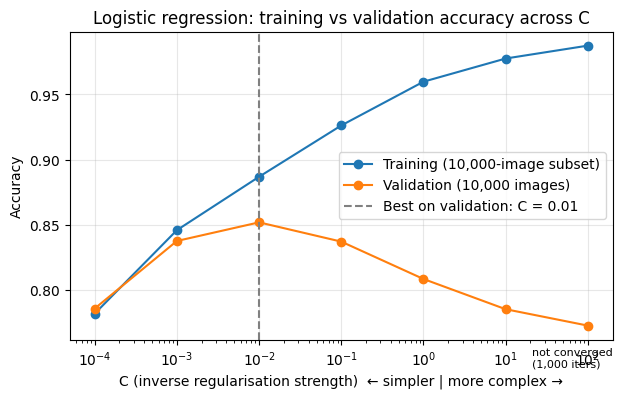

In [28]:
# Pull each column out of the results
Cs = [r["C"] for r in lr_results]
lr_train = [r["train_acc"] for r in lr_results]
lr_val = [r["val_acc"] for r in lr_results]
best_sub = max(lr_results, key=lambda r: r["val_acc"])

plt.figure(figsize=(7, 4))
plt.plot(Cs, lr_train, marker="o", label="Training (10,000-image subset)")
plt.plot(Cs, lr_val, marker="o", label="Validation (10,000 images)")
plt.axvline(best_sub["C"], linestyle="--", color="gray", label=f"Best on validation: C = {best_sub['C']}")

# Label any fit that hit the iteration limit
for r in lr_results:
    if not r["converged"]:
        plt.annotate("not converged\n(1,000 iters)", (r["C"], r["val_acc"]),
                     textcoords="offset points", xytext=(-40, -30), fontsize=8)

plt.xscale("log")
plt.xlabel("C (inverse regularisation strength)  ← simpler | more complex →")
plt.ylabel("Accuracy")
plt.title("Logistic regression: training vs validation accuracy across C")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Choosing C on the full training set

The C = 1 model behaves very differently depending on how much data it is trained on:

| C = 1 | Trained on | Validation | Gap |
|---|---|---|---|
| Baseline | 50,000 images | 85.48% | 3.3 points |
| Sweep | 10,000 images | 80.83% | 15.2 points |

The **same C overfits much more with less data**, so the best C on 10,000 images may not be the best C on 50,000.
The final C is therefore chosen on the **full training set** from three candidates: C = 0.01 (the subset's best),
C = 0.1, and C = 1 (already fitted as the baseline). The choice is still made on validation only (R1).

In [29]:
# Validation accuracy for each candidate C, trained on all 50,000 images
full_results = {1.0: log_reg_val_acc}   # C = 1 is the baseline fitted earlier

for C in [0.01, 0.1]:
    model = LogisticRegression(C=C, max_iter=MAX_ITER, random_state=SEED)
    start = time.time()
    model.fit(X_train_scaled, y_train)
    elapsed = time.time() - start
    val_acc = accuracy_score(y_val, model.predict(X_val_scaled))
    full_results[C] = val_acc
    print(f"C = {C:<5}  val {val_acc:.4f}   iters {model.n_iter_[0]}   ({elapsed:.0f} s)")

# The C with the highest validation accuracy
best_C = max(full_results, key=full_results.get)
print(f"\nBest C on full training set: {best_C} (val {full_results[best_C]:.4f})")

C = 0.01   val 0.8640   iters 473   (160 s)
C = 0.1    val 0.8613   iters 760   (256 s)

Best C on full training set: 0.01 (val 0.8640)


| C (all 50,000 images) | Validation | Iterations | Time |
|---|---|---|---|
| **0.01** | **86.40%** | 473 | 191 s |
| 0.1 | 86.13% | 760 | 257 s |
| 1 (baseline) | 85.48% | 883 | 357 s |

All three converged. **C = 0.01 is selected**, agreeing with the subset sweep. With 50,000 images the three values
are within 1 point of each other (compared with 4.4 points on the 10,000-image subset), which supports the idea
that more data reduces overfitting, so the exact choice of C matters less. Stronger regularisation also needs
fewer iterations, so it trains faster.

### Final selected models

The selected settings are refitted under clear names, so that 1.2, 1.3 and 1.5 use exactly these models.

In [30]:
# Final logistic regression with the C selected on validation
final_log_reg = LogisticRegression(C=best_C, max_iter=MAX_ITER, random_state=SEED)

start = time.time()
final_log_reg.fit(X_train_scaled, y_train)
print(f"Fit time: {time.time() - start:.0f} s   iterations: {final_log_reg.n_iter_[0]}")

final_lr_train_acc = accuracy_score(y_train, final_log_reg.predict(X_train_scaled))
final_lr_val_acc = accuracy_score(y_val, final_log_reg.predict(X_val_scaled))
print(f"Final logistic regression (C = {best_C}): train {final_lr_train_acc:.4f}   val {final_lr_val_acc:.4f}")

Fit time: 158 s   iterations: 473
Final logistic regression (C = 0.01): train 0.8750   val 0.8640


In [31]:
# Final kNN with the k selected on validation (taken from the sweep, not typed in)
best_k = best["k"]
final_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
final_knn.fit(X_train, y_train)
print(f"Final kNN: k = {best_k}")

Final kNN: k = 7


The refitted logistic regression gives exactly the same validation accuracy (**86.40%**) and iteration count (**473**)
as in the comparison above, which confirms the results are reproducible. Its train−validation gap is only
**1.1 points** (87.50% vs 86.40%), compared with 3.3 points at C = 1: stronger regularisation both **reduced
overfitting and improved validation accuracy**.

| Name | Model | Setting | Validation accuracy |
|---|---|---|---|
| `final_log_reg` | Logistic regression | C = 0.01 | 86.40% |
| `final_knn` | kNN | k = 7 | 86.17% |

## 1.2 Metrics

All results in this section are on the **validation set** (1,000 images per class), using the settings selected
in 1.4: logistic regression with **C = 0.01** and kNN with **k = 7**.

For each class, the report shows:

- **Precision:** of the images the model called this class, the fraction that really were this class.
- **Recall:** of the real images of this class, the fraction the model found.
- **F1:** a single score that balances precision and recall.
- **Support:** how many images of this class are in the validation set, so readers can interpret the proportions.

In [32]:
# Class names instead of 0-9 in all reports
class_names = train_data.classes

# Predictions from the final models (saved so 1.3 can reuse them without waiting again)
lr_val_pred = final_log_reg.predict(X_val_scaled)
knn_val_pred = final_knn.predict(X_val)          # about a minute

print(f"Validation accuracy, logistic regression (C = {best_C}): {accuracy_score(y_val, lr_val_pred):.4f}")
print(f"Validation accuracy, kNN (k = {best_k}):                  {accuracy_score(y_val, knn_val_pred):.4f}")

Validation accuracy, logistic regression (C = 0.01): 0.8640
Validation accuracy, kNN (k = 7):                  0.8617


On the validation set, the selected logistic regression reached **86.40%** accuracy and the selected kNN reached
**86.17%**. The difference of 0.23 percentage points (23 images out of 10,000) is small, so the two models perform
similarly overall. The class-level results below show where they differ.

In [33]:
# Precision, recall, F1 and support for every class
print(f"Logistic regression (C = {best_C}), validation set\n")
print(classification_report(y_val, lr_val_pred, target_names=class_names, digits=3))

print(f"\nkNN (k = {best_k}), validation set\n")
print(classification_report(y_val, knn_val_pred, target_names=class_names, digits=3))

Logistic regression (C = 0.01), validation set

              precision    recall  f1-score   support

 T-shirt/top      0.805     0.851     0.827      1000
     Trouser      0.981     0.969     0.975      1000
    Pullover      0.766     0.768     0.767      1000
       Dress      0.860     0.872     0.866      1000
        Coat      0.767     0.785     0.776      1000
      Sandal      0.936     0.943     0.939      1000
       Shirt      0.681     0.622     0.650      1000
     Sneaker      0.926     0.928     0.927      1000
         Bag      0.957     0.952     0.954      1000
  Ankle boot      0.953     0.950     0.951      1000

    accuracy                          0.864     10000
   macro avg      0.863     0.864     0.863     10000
weighted avg      0.863     0.864     0.863     10000


kNN (k = 7), validation set

              precision    recall  f1-score   support

 T-shirt/top      0.792     0.900     0.842      1000
     Trouser      0.991     0.964     0.977      1000


**Easy and hard classes.** **Trouser, Bag and Ankle boot** are the easiest classes (F1 above 0.93 for both models),
because their shapes are distinctive. **Shirt** is the hardest class for both models (F1 0.650 and 0.656; recall
**0.622** for both), followed by **Pullover** and **Coat**. These are all upper-body garments whose outlines are
very similar at 28 × 28 pixels.

Because every class has a support of 1,000, the macro average (a plain average over classes) and the weighted
average (weighted by support) are almost identical.

In [34]:
# The same reports as dictionaries, so single numbers can be picked out
lr_report = classification_report(y_val, lr_val_pred, target_names=class_names, output_dict=True)
knn_report = classification_report(y_val, knn_val_pred, target_names=class_names, output_dict=True)

# Recall for each class, side by side
print(f"{'Class':<12} {'Support':>7}  {'LogReg recall':>13}  {'kNN recall':>10}")
for name in class_names:
    print(f"{name:<12} {lr_report[name]['support']:>7.0f}  "
          f"{lr_report[name]['recall']:>13.3f}  {knn_report[name]['recall']:>10.3f}")

Class        Support  LogReg recall  kNN recall
T-shirt/top     1000          0.851       0.900
Trouser         1000          0.969       0.964
Pullover        1000          0.768       0.808
Dress           1000          0.872       0.857
Coat            1000          0.785       0.755
Sandal          1000          0.943       0.828
Shirt           1000          0.622       0.622
Sneaker         1000          0.928       0.957
Bag             1000          0.952       0.954
Ankle boot      1000          0.950       0.972


**Overall accuracy hides real differences.** The models are only 0.23 points apart overall, but differ by up to
**11.5 points** on a single class:

- **Sandal:** logistic regression 0.943 vs kNN 0.828. kNN's Sandal *precision* is almost perfect (0.999), but it
  misses about 17% of sandals.
- **T-shirt, Pullover, Sneaker and Ankle boot:** kNN has **higher recall but lower precision**, meaning it
  assigns images to these classes more readily.
- **Shirt:** exactly the same recall (0.622) for both, so it is equally hard for both approaches.

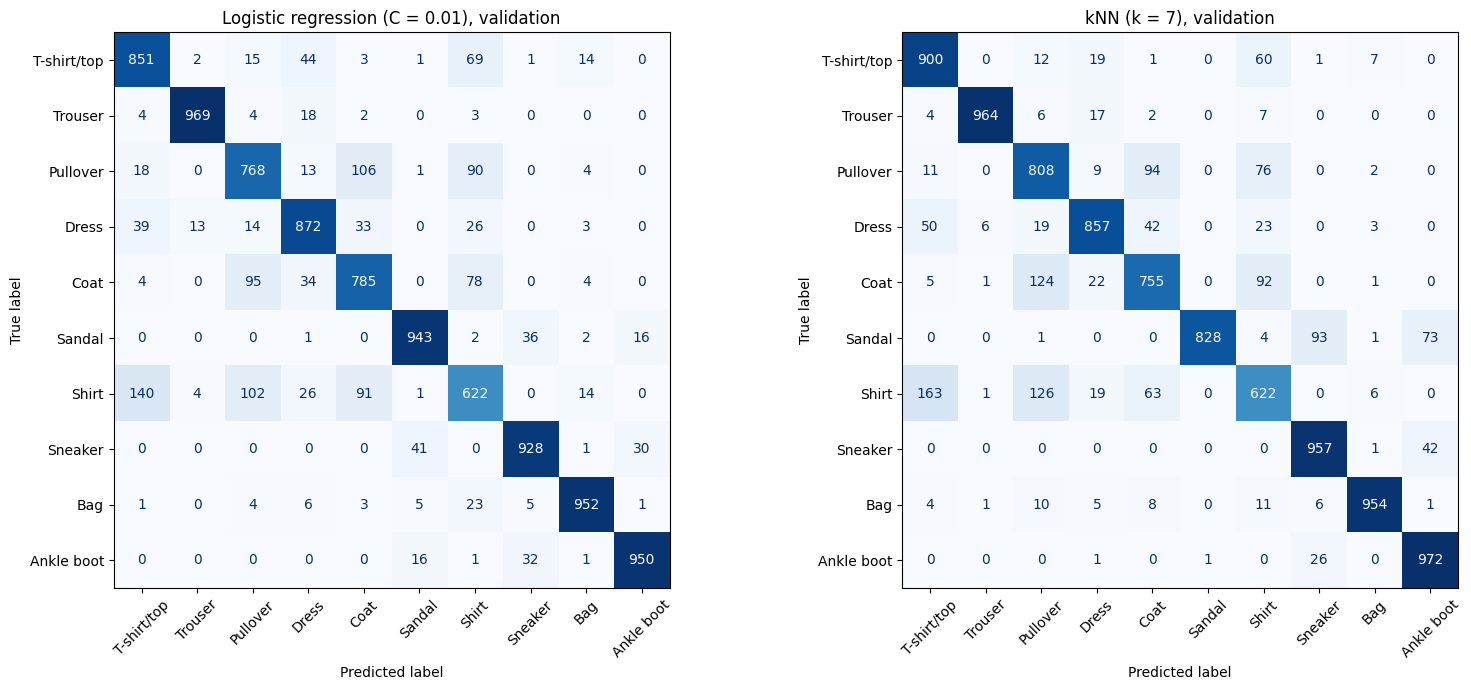

In [35]:
# Rows = true class, columns = predicted class; the diagonal holds correct predictions
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ConfusionMatrixDisplay.from_predictions(
    y_val, lr_val_pred, display_labels=class_names,
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Logistic regression (C = {best_C}), validation")

ConfusionMatrixDisplay.from_predictions(
    y_val, knn_val_pred, display_labels=class_names,
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title(f"kNN (k = {best_k}), validation")

plt.tight_layout()
plt.show()

**Confusion matrices.** Almost all errors happen **within groups of similar shapes**:

- **Upper-body garments are confused with each other.** Shirts are most often predicted as T-shirts (140 for
  logistic regression, 163 for kNN), pullovers (102 and 126) and coats (91 and 63). Pullovers and coats are
  confused in **both directions** (e.g. 106 pullovers predicted as coats by logistic regression, and 124 coats
  predicted as pullovers by kNN).
- **Footwear is confused only with other footwear.**
- **Almost no images are confused between clothing and footwear**, and Trousers and Bags are rarely confused with anything.

**kNN and sandals.** kNN's low Sandal recall comes from **93 sandals predicted as Sneakers and 73 as Ankle boots**.
In the Sandal column, kNN predicts "Sandal" for only **one** image that is not a sandal, which explains its
precision of 0.999. Logistic regression sends only 36 sandals to Sneaker and 16 to Ankle boot. This is examined
further in 1.3.

So both models learn the **overall shape** of an item well, but struggle with the **fine details** that separate
classes within a shape group, which 28 × 28 pixels barely show.

## 1.3 Error analysis

Every validation image is sorted into four groups depending on which model classified it correctly. A seeded
sample from each group is then inspected, with **both models' predictions on the same images**.

In [36]:
# True/False for each of the 10,000 validation images
lr_correct = (lr_val_pred == y_val)
knn_correct = (knn_val_pred == y_val)

# & means "and", ~ means "not"; np.where(...)[0] gives the matching row numbers in X_val
groups = {
    "Both correct":        np.where(lr_correct & knn_correct)[0],
    "Both wrong":          np.where(~lr_correct & ~knn_correct)[0],
    "Only LogReg correct": np.where(lr_correct & ~knn_correct)[0],
    "Only kNN correct":    np.where(~lr_correct & knn_correct)[0],
}

for name, rows in groups.items():
    print(f"{name:<20} {len(rows):>5} images")

Both correct          8045 images
Both wrong             788 images
Only LogReg correct    595 images
Only kNN correct       572 images


The four groups add up to 10,000 and match the accuracies (8,045 + 595 = 8,640 for logistic regression;
8,045 + 572 = 8,617 for kNN).

The models **agree on 88.3%** of validation images (8,045 both correct, 788 both wrong) but **disagree on the
remaining 1,167 (11.7%)**: 595 are correct only for logistic regression and 572 only for kNN. Although their
overall accuracy differs by only 23 images, about **42% of each model's errors are not made by the other model**
(logistic regression makes 1,360 errors and kNN 1,383, of which 788 are shared). This reflects their different
ways of using the pixels.

Both correct: X_val rows [4349, 901, 6530, 7745] (original indices [52500, 2662, 16347, 37936])
Both wrong: X_val rows [6995, 2127, 957, 5561] (original indices [46736, 11613, 13868, 45198])
Only LogReg correct: X_val rows [7125, 5118, 7699, 1392] (original indices [39088, 35108, 20124, 3889])
Only kNN correct: X_val rows [3717, 7755, 1786, 9098] (original indices [24237, 46750, 45674, 5086])


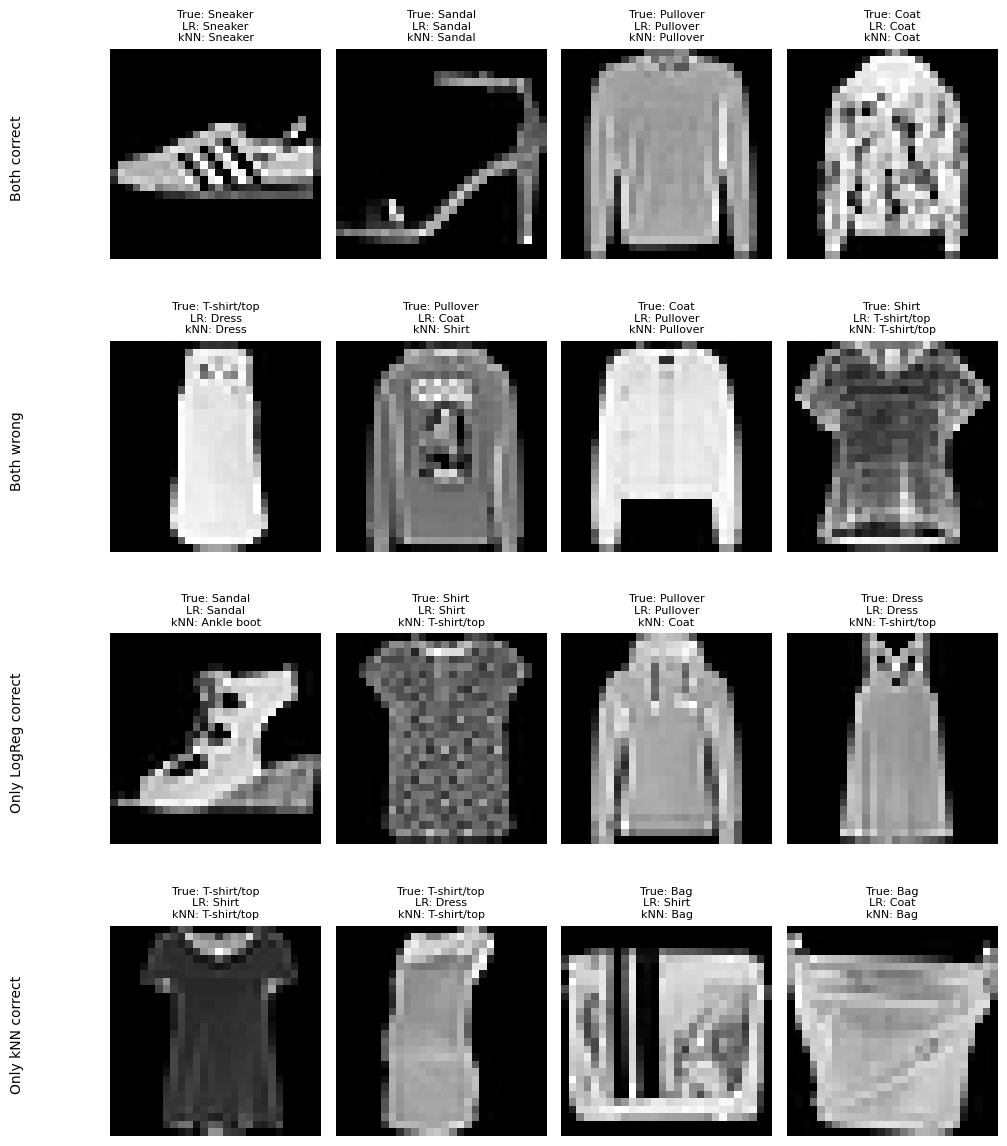

In [37]:
# Seeded generator, so the same 16 images are shown on every run
rng_errors = np.random.default_rng(SEED)
n_per_group = 4

fig, axes = plt.subplots(4, n_per_group, figsize=(10, 12))

for row, (group_name, rows) in enumerate(groups.items()):
    # 4 different images from this group
    chosen = rng_errors.choice(rows, size=n_per_group, replace=False)
    # Record both index types: row in X_val and position in the original 60,000 images
    print(f"{group_name}: X_val rows {chosen.tolist()} "
          f"(original indices {[val_indices[i] for i in chosen]})")

    for col, i in enumerate(chosen):
        ax = axes[row, col]
        ax.imshow(X_val[i].reshape(28, 28), cmap="gray", interpolation="nearest")
        ax.set_title(f"True: {class_names[y_val[i]]}\n"
                     f"LR: {class_names[lr_val_pred[i]]}\n"
                     f"kNN: {class_names[knn_val_pred[i]]}", fontsize=8)
        ax.axis("off")

    # Group name down the left-hand side of each row
    axes[row, 0].text(-12, 14, group_name, rotation=90, va="center", ha="right", fontsize=10)

plt.tight_layout()
plt.show()

**Inspected examples (seeded sample, seed 42).** "X_val rows" are positions in the 10,000-image validation array;
"original indices" are the matching positions in the official 60,000-image training set (via `val_indices`).

- **Both correct:** typical examples with clear outlines, including a striped sneaker (row 4349), a thin-strapped
  high-heeled sandal (row 901), a plain pullover (row 6530), and a patterned coat (row 7745). The coat shows that a
  strong pattern does not prevent recognition when the outline is clear.
- **Both wrong:** genuinely ambiguous images. A long sleeveless top labelled T-shirt/top (row 6995) was predicted as
  Dress by both models. A short-sleeved patterned shirt (row 5561) was predicted as T-shirt by both, because its
  collar is barely visible at this resolution. A short white coat with no visible zip or buttons (row 957) was
  predicted as Pullover by both. A pullover with a large printed graphic (row 2127) received a different wrong
  answer from each model (Coat and Shirt). A person might well make the same mistakes.
- **Only logistic regression correct:** kNN predicted a chunky wedge sandal as an Ankle boot (row 7125), a
  short-sleeved shirt as a T-shirt (row 5118), a hoodie-style pullover as a Coat (row 7699), and a strappy dress as
  a T-shirt/top (row 1392).
- **Only kNN correct:** logistic regression predicted a dark, low-contrast T-shirt as a Shirt (row 3717), a long
  sleeveless top as a Dress (row 7755), a bag with strong vertical stripes as a Shirt (row 1786), and a wide, faint
  bucket bag as a Coat (row 9098). Row 7755 is similar to row 6995, so long sleeveless tops seem genuinely ambiguous
  between T-shirt/top and Dress.

**How the errors relate to how each model works.** Logistic regression learns **one set of pixel weights per
class**, a kind of template, so it struggles with **unusual examples** whose bright pixels fall where another
class's features normally are (for example, the bag's vertical stripes resembling sleeves). kNN compares an image
with stored training images, so it can classify unusual variants correctly **when similar examples exist in the
training set**, but fails when a variant looks more like another class's images, as with the wedge sandal predicted
as an Ankle boot. The thin-strapped sandal (row 901) was classified correctly by both, which suggests kNN's sandal
errors may involve solid, boot-like sandals rather than strappy ones. These interpretations are based on a small
sample and are offered as explanations, not proven rules.

In [38]:
# For each class: how many of its 1,000 validation images neither model gets right
print(f"{'Class':<12} {'Both wrong':>10}  (out of 1,000)")
for c, name in enumerate(class_names):
    both_wrong = np.sum((y_val == c) & ~lr_correct & ~knn_correct)
    print(f"{name:<12} {both_wrong:>10}")

Class        Both wrong  (out of 1,000)
T-shirt/top          65
Trouser              25
Pullover            120
Dress                84
Coat                133
Sandal               48
Shirt               248
Sneaker              20
Bag                  26
Ankle boot           19


**Easy and hard classes.** The counts add up to the 788 shared errors.

- **Easiest:** Ankle boot (19), Sneaker (20), Trouser (25) and Bag (26). Fewer than 3% of their images are
  misclassified by both models; their shapes are distinctive and rarely overlap with other classes.
- **Hardest:** **Shirt (248)**, by far. About one in four shirts fools both models, and shirts make up **31%** of all
  shared errors. Coat (133) and Pullover (120) follow.
- The five upper-body classes (T-shirt/top, Pullover, Dress, Coat, Shirt) account for **650 of the 788 shared errors
  (82%)**, because at 28 × 28 pixels they share the same outline and differ mainly in small details such as collars,
  buttons and sleeve length.
- **Sandal (48)** is low here even though kNN misclassifies 172 sandals. Most of kNN's sandal errors are therefore
  specific to how it compares whole images: logistic regression classifies about 124 of those sandals correctly.

Inspecting validation images to understand the models is allowed, but no settings were changed as a result (R7).

## 1.5 Decisions and costs: Shirt vs not Shirt

**Scenario.** A warehouse sorts returned clothing. Items predicted as **Shirt** go to a station where they are ironed
before resale; everything else goes to the normal packing line.

- A **false negative** (a shirt sent to the normal line) means a creased shirt is resold, which risks a complaint or
  another return.
- A **false positive** (a non-shirt sent to the shirt station) only costs a worker a few seconds to move it back.

Missing a shirt is therefore assumed to cost **5 times** as much as a false alarm (C_FN = 5, C_FP = 1). This ratio
is an assumption, so other ratios are also examined.

**Why Shirt.** Shirt is the hardest class (recall 0.622 for both models; see 1.2 and 1.3), so the threshold has a
real effect; a near-trivial task such as "footwear vs not footwear" would not show a meaningful trade-off. Only 10%
of validation images are shirts, so accuracy alone would be misleading: a model that never predicts Shirt would
still be 90% accurate.

**Method.** The selected logistic regression (C = 0.01) gives a probability of Shirt for each validation image. An
item is flagged as a shirt if this probability is at least a threshold t. kNN is not used here, because its scores
are neighbour vote fractions rather than probabilities.

In [39]:
SHIRT = class_names.index("Shirt")      # the label number for Shirt (6)

# predict_proba gives 10 probabilities per image; keep the "Shirt" column (found safely, not assumed)
shirt_col = list(final_log_reg.classes_).index(SHIRT)
val_shirt_proba = final_log_reg.predict_proba(X_val_scaled)[:, shirt_col]

y_val_shirt = (y_val == SHIRT).astype(int)   # 1 = Shirt, 0 = not Shirt

print("Shirt label number:", SHIRT)
print("Validation shirts:    ", y_val_shirt.sum())
print("Validation non-shirts:", (y_val_shirt == 0).sum())
print("Example probabilities:", np.round(val_shirt_proba[:5], 3))

Shirt label number: 6
Validation shirts:     1000
Validation non-shirts: 9000
Example probabilities: [0.002 0.001 0.183 0.    0.575]


In [40]:
COST_FN = 5   # a missed shirt: resold creased, likely complaint or return
COST_FP = 1   # a non-shirt sent to the shirt station: a worker moves it back

thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)   # 0.05, 0.10, ..., 0.95
threshold_results = []

for t in thresholds:
    # Flag as Shirt if P(Shirt) is at least t
    pred = (val_shirt_proba >= t).astype(int)

    tp = np.sum((pred == 1) & (y_val_shirt == 1))   # shirts correctly flagged
    fp = np.sum((pred == 1) & (y_val_shirt == 0))   # non-shirts wrongly flagged
    fn = np.sum((pred == 0) & (y_val_shirt == 1))   # shirts missed
    tn = np.sum((pred == 0) & (y_val_shirt == 0))   # non-shirts correctly passed

    # The if/else avoids dividing by zero when nothing is flagged
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn)
    cost = COST_FN * fn + COST_FP * fp

    threshold_results.append({"t": t, "tp": tp, "fp": fp, "fn": fn, "tn": tn,
                              "precision": precision, "recall": recall, "cost": cost})

print(f"{'Thresh':>6} {'TP':>5} {'FP':>5} {'FN':>5} {'Prec':>6} {'Recall':>6} {'Cost':>6}")
for r in threshold_results:
    print(f"{r['t']:>6.2f} {r['tp']:>5} {r['fp']:>5} {r['fn']:>5} "
          f"{r['precision']:>6.3f} {r['recall']:>6.3f} {r['cost']:>6}")

Thresh    TP    FP    FN   Prec Recall   Cost
  0.05   960  2000    40  0.324  0.960   2200
  0.10   910  1340    90  0.404  0.910   1790
  0.15   860  1013   140  0.459  0.860   1713
  0.20   815   782   185  0.510  0.815   1707
  0.25   765   604   235  0.559  0.765   1779
  0.30   720   472   280  0.604  0.720   1872
  0.35   677   384   323  0.638  0.677   1999
  0.40   637   312   363  0.671  0.637   2127
  0.45   598   239   402  0.714  0.598   2249
  0.50   549   189   451  0.744  0.549   2444
  0.55   509   144   491  0.779  0.509   2599
  0.60   466   120   534  0.795  0.466   2790
  0.65   420    88   580  0.827  0.420   2988
  0.70   368    66   632  0.848  0.368   3226
  0.75   294    47   706  0.862  0.294   3577
  0.80   219    33   781  0.869  0.219   3938
  0.85   158    19   842  0.893  0.158   4229
  0.90    85     9   915  0.904  0.085   4584
  0.95    33     2   967  0.943  0.033   4837


**The trade-off.** Nineteen thresholds from 0.05 to 0.95 were tested. Raising the threshold **lowers false positives**
(from 2,000 at t = 0.05 to 2 at t = 0.95) but **raises false negatives** (from 40 to 967), so one error can only be
reduced at the expense of the other. Precision rises (0.32 → 0.94) while recall falls (0.96 → 0.03). In every row,
TP + FN = 1,000 shirts.

**A subtle point.** At t = 0.5, Shirt recall is **0.549**, lower than the **0.622** in the 10-class report (1.2). The
10-class model predicts whichever class has the **highest** probability, so an image can be called "Shirt" with a
probability below 0.5 if every other class is lower. The yes/no rule here requires at least t.

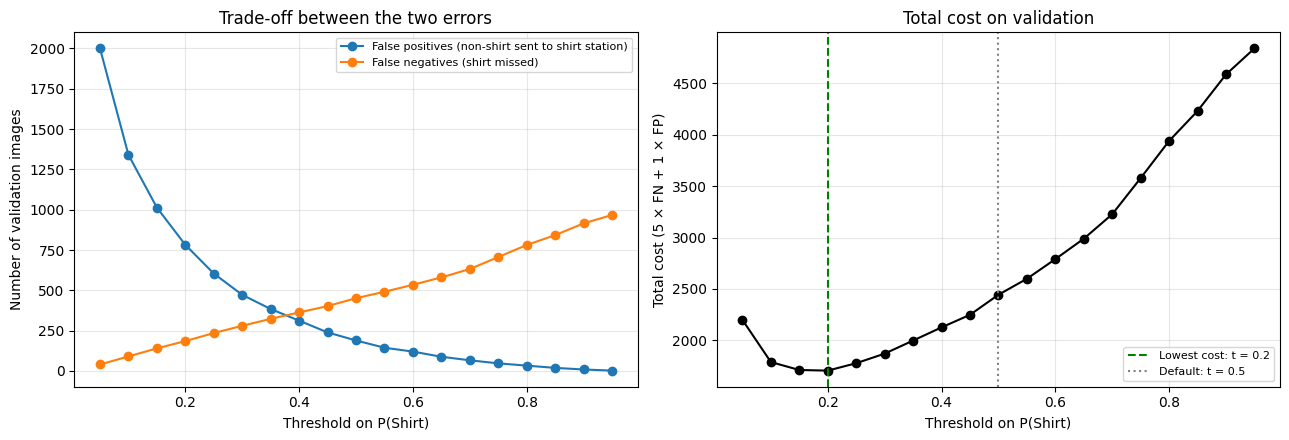

Chosen threshold: 0.2  cost 1707  (FN 185, FP 782, recall 0.815, precision 0.510)
Default 0.5:      cost 2444  (FN 451, FP 189, recall 0.549, precision 0.744)


In [41]:
# Columns for plotting
ts = [r["t"] for r in threshold_results]
fps = [r["fp"] for r in threshold_results]
fns = [r["fn"] for r in threshold_results]
costs = [r["cost"] for r in threshold_results]

# Lowest-cost threshold (chosen by code) and the default 0.5 for comparison
best_t = min(threshold_results, key=lambda r: r["cost"])
default = next(r for r in threshold_results if r["t"] == 0.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: how the two errors trade off
axes[0].plot(ts, fps, marker="o", label="False positives (non-shirt sent to shirt station)")
axes[0].plot(ts, fns, marker="o", label="False negatives (shirt missed)")
axes[0].set_xlabel("Threshold on P(Shirt)")
axes[0].set_ylabel("Number of validation images")
axes[0].set_title("Trade-off between the two errors")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Right: total cost, with the chosen operating point and the default
axes[1].plot(ts, costs, marker="o", color="black")
axes[1].axvline(best_t["t"], linestyle="--", color="green", label=f"Lowest cost: t = {best_t['t']}")
axes[1].axvline(0.5, linestyle=":", color="gray", label="Default: t = 0.5")
axes[1].set_xlabel("Threshold on P(Shirt)")
axes[1].set_ylabel(f"Total cost ({COST_FN} × FN + {COST_FP} × FP)")
axes[1].set_title("Total cost on validation")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Chosen threshold: {best_t['t']}  cost {best_t['cost']}  "
      f"(FN {best_t['fn']}, FP {best_t['fp']}, recall {best_t['recall']:.3f}, precision {best_t['precision']:.3f})")
print(f"Default 0.5:      cost {default['cost']}  "
      f"(FN {default['fn']}, FP {default['fp']}, recall {default['recall']:.3f}, precision {default['precision']:.3f})")

**Chosen operating point.** The lowest total cost is at **t = 0.20** (cost 1,707: 185 shirts missed, 782 false alarms,
recall 0.815, precision 0.510).

| | t = 0.20 (chosen) | t = 0.50 (default) |
|---|---|---|
| Shirts caught (TP) | 815 | 549 |
| Shirts missed (FN) | 185 | 451 |
| False alarms (FP) | 782 | 189 |
| Recall | 0.815 | 0.549 |
| Precision | 0.510 | 0.744 |
| **Total cost** | **1,707** | 2,444 |

Moving from 0.5 to 0.2 **reduces cost by about 30%**: it catches 266 more shirts in exchange for 593 more false
alarms, which is worthwhile because a missed shirt costs 5 times as much. At this point, about half the items sent
to the shirt station really are shirts.

The cost curve has a **flat bottom** between t = 0.15 and 0.20 (1,713 vs 1,707), so any threshold in that range
performs almost equally well. To the right the curve rises steeply, so setting the threshold **too high is much
more costly** than setting it too low.

In [42]:
# Best threshold for different FN:FP cost ratios (FP cost fixed at 1)
print(f"{'FN:FP cost ratio':>16} {'Best threshold':>15} {'FN':>5} {'FP':>5}")
for ratio in [1, 2, 5, 10, 20]:
    # Named best_for_ratio so it does not overwrite `best` (the kNN sweep result)
    best_for_ratio = min(threshold_results, key=lambda r: ratio * r["fn"] + 1 * r["fp"])
    print(f"{ratio:>13}:1 {best_for_ratio['t']:>15.2f} {best_for_ratio['fn']:>5} {best_for_ratio['fp']:>5}")

FN:FP cost ratio  Best threshold    FN    FP
            1:1            0.55   491   144
            2:1            0.35   323   384
            5:1            0.20   185   782
           10:1            0.10    90  1340
           20:1            0.05    40  2000


**Sensitivity to the cost ratio.** The best threshold falls steadily as missing a shirt becomes more expensive:
**0.55 (1:1), 0.35 (2:1), 0.20 (5:1), 0.10 (10:1) and 0.05 (20:1)**. Each step accepts more false alarms to miss
fewer shirts.

These are close to the theoretical optimum **t = C_FP / (C_FP + C_FN)**, which is 0.50, 0.33, 0.17, 0.09 and 0.05.
The reasoning: flagging an item costs C_FP × (1 − p) in expectation and not flagging it costs C_FN × p, so flagging
is cheaper when p > C_FP / (C_FP + C_FN). The close match suggests that logistic regression's probabilities are
reasonably well calibrated on this task; the small differences come from testing thresholds in steps of 0.05. For
20:1 the best value lies at the **edge** of the tested range, so the true optimum may be lower.

**Final choice:** t = **0.20**, selected on validation. It will be recorded in the test plan and applied unchanged
to the test set (R6).

## Part 1 conclusions: which model is better?

**On accuracy, the two models are effectively tied.** Logistic regression (C = 0.01) reached **86.40%** and kNN
(k = 7) **86.17%** on validation, a difference of 23 images out of 10,000. This comes from **one split and one
seed**, so it is not evidence that one model is more accurate than the other.

**Overall, logistic regression is the more suitable choice for this task**, for practical reasons:

| | Logistic regression (C = 0.01) | kNN (k = 7) |
|---|---|---|
| Validation accuracy | 86.40% | 86.17% |
| Train − val gap | 1.1 points | 2.7 points |
| Fitting time | ~190 s (once) | ~0.1 s |
| Prediction time (10,000 images) | fast | ~45 s |
| What it stores | 10 × 784 weights | all 50,000 training images |
| Probabilities for decisions (1.5) | yes | no (vote fractions) |
| Weakest class | Shirt (recall 0.622) | Shirt (0.622); Sandal (0.828) |

- Logistic regression **predicts much faster** and stores far less, because it keeps only its weights.
- It **generalises with a smaller gap** at its selected setting.
- It gives **probabilities**, which made the cost-based threshold study possible.
- kNN has no training cost and handles some unusual variants better (for example, the striped and bucket bags in
  1.3), but its prediction time grows with the size of the training set, and it struggles with Sandal.

**What their errors tell us.** Both models find the **overall shape** of an item easy (trousers, bags and footwear are
rarely confused with clothing) but struggle with **fine details within a shape group**, especially Shirt versus
T-shirt, Pullover and Coat. About 42% of each model's errors are not shared by the other, because one learns a
template per class and the other compares whole images.

# Part 2 — Neural networks: architecture and learning

In [43]:
class MLP(nn.Module):
    """A feed-forward network: flatten -> hidden layers with ReLU -> 10 class scores."""

    def __init__(self, hidden_sizes):
        super().__init__()
        layers = []
        in_size = 784                               # 28 x 28 pixels
        for h in hidden_sizes:
            layers.append(nn.Linear(in_size, h))    # weights and biases
            layers.append(nn.ReLU())                # non-linearity
            in_size = h
        layers.append(nn.Linear(in_size, 10))       # one score per class (no softmax here)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)                   # [batch, 1, 28, 28] -> [batch, 784]
        return self.net(x)


def count_parameters(model):
    """Number of trainable weights and biases."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


BASELINE_HIDDEN = [256, 128]

torch.manual_seed(SEED)                             # fixes the initial weights
baseline_model = MLP(BASELINE_HIDDEN).to(device)

print(baseline_model)
print("Trainable parameters:", count_parameters(baseline_model))

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 235146


In [44]:
loss_fn = nn.CrossEntropyLoss()      # softmax + negative log-likelihood, averaged over the batch


def train_one_epoch(model, loader, lr):
    """One pass over the training data, updating the weights after every batch (plain SGD)."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        # 1. Forward pass: compute class scores and the loss
        logits = model(images)
        loss = loss_fn(logits, labels)

        # 2. Backward pass: autodiff computes d(loss)/d(parameter) for every weight and bias
        model.zero_grad()            # clear gradients from the previous batch
        loss.backward()

        # 3. Gradient update (plain SGD): move each parameter a small step against its gradient
        with torch.no_grad():
            for p in model.parameters():
                p -= lr * p.grad

        # Keep running totals for this epoch
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        n += labels.size(0)

    return total_loss / n, correct / n


def evaluate(model, loader):
    """Loss and accuracy on a dataset, without changing the weights."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0

    with torch.no_grad():            # no gradients needed for evaluation
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += loss_fn(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            n += labels.size(0)

    return total_loss / n, correct / n

In [45]:
def train_model(hidden_sizes, lr=0.1, epochs=20, seed=SEED, name="model"):
    """Train an MLP from scratch and keep the epoch with the best validation accuracy."""
    torch.manual_seed(seed)                  # same initial weights for the same seed
    _ = g.manual_seed(seed)                  # same training shuffle order for every run (R4)
    model = MLP(hidden_sizes).to(device)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, lr)
        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Checkpoint rule: keep a copy of the weights with the best validation accuracy so far
        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())

        print(f"{name} | epoch {epoch:>2}: train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    elapsed = time.time() - start
    model.load_state_dict(best_state)        # restore the best checkpoint

    os.makedirs("checkpoints", exist_ok=True)
    torch.save(best_state, f"checkpoints/{name}.pt")

    summary = {"name": name, "hidden": hidden_sizes, "lr": lr, "params": count_parameters(model),
               "best_epoch": best_epoch, "best_val_acc": best_val_acc,
               "final_train_loss": history["train_loss"][-1], "time_s": elapsed}
    print(f"\n{name}: best val acc {best_val_acc:.4f} at epoch {best_epoch}, "
          f"{summary['params']:,} parameters, {elapsed:.0f} s")
    return model, history, summary

In [46]:
baseline_model, baseline_hist, baseline_summary = train_model(BASELINE_HIDDEN, lr=0.1, epochs=20, name="baseline")

baseline | epoch  1: train loss 0.7278 acc 0.7408 | val loss 0.6490 acc 0.7691
baseline | epoch  2: train loss 0.4550 acc 0.8352 | val loss 0.5814 acc 0.7826
baseline | epoch  3: train loss 0.3999 acc 0.8535 | val loss 0.4468 acc 0.8332
baseline | epoch  4: train loss 0.3706 acc 0.8635 | val loss 0.4458 acc 0.8370
baseline | epoch  5: train loss 0.3467 acc 0.8725 | val loss 0.4282 acc 0.8470
baseline | epoch  6: train loss 0.3297 acc 0.8775 | val loss 0.4806 acc 0.8248
baseline | epoch  7: train loss 0.3141 acc 0.8845 | val loss 0.3775 acc 0.8571
baseline | epoch  8: train loss 0.3016 acc 0.8874 | val loss 0.4654 acc 0.8247
baseline | epoch  9: train loss 0.2902 acc 0.8925 | val loss 0.3375 acc 0.8793
baseline | epoch 10: train loss 0.2805 acc 0.8946 | val loss 0.3448 acc 0.8723
baseline | epoch 11: train loss 0.2716 acc 0.8986 | val loss 0.3173 acc 0.8836
baseline | epoch 12: train loss 0.2615 acc 0.9012 | val loss 0.2997 acc 0.8893
baseline | epoch 13: train loss 0.2542 acc 0.9047 | 

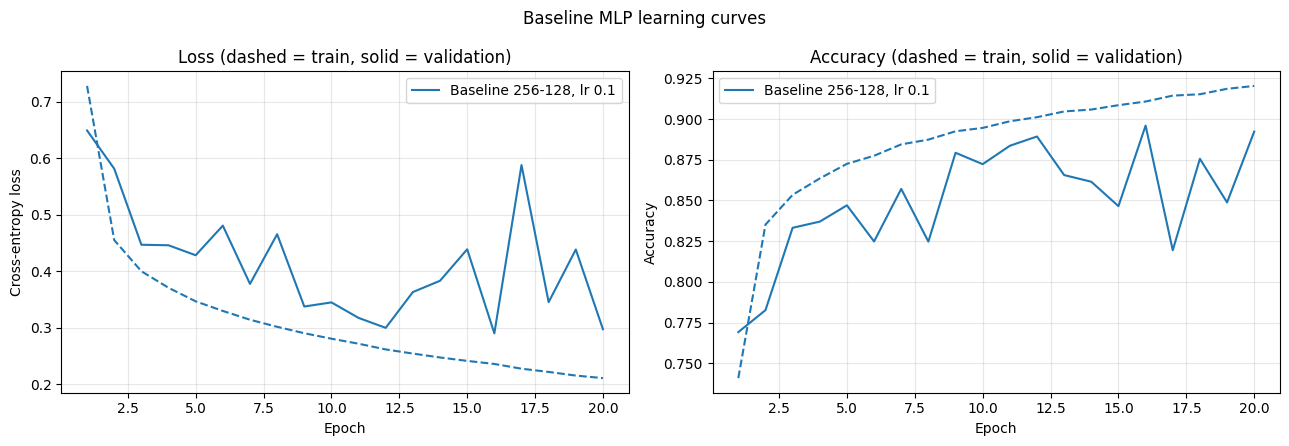

In [47]:
def plot_curves(histories, title):
    """Loss and accuracy per epoch; dashed = training, solid = validation."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for label, h in histories.items():
        epochs = range(1, len(h["train_loss"]) + 1)
        line, = axes[0].plot(epochs, h["train_loss"], linestyle="--")
        axes[0].plot(epochs, h["val_loss"], color=line.get_color(), label=label)
        axes[1].plot(epochs, h["train_acc"], linestyle="--", color=line.get_color())
        axes[1].plot(epochs, h["val_acc"], color=line.get_color(), label=label)

    axes[0].set_title("Loss (dashed = train, solid = validation)")
    axes[1].set_title("Accuracy (dashed = train, solid = validation)")
    for ax, ylabel in zip(axes, ["Cross-entropy loss", "Accuracy"]):
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_curves({"Baseline 256-128, lr 0.1": baseline_hist}, "Baseline MLP learning curves")

In [48]:
small_model, small_hist, small_summary = train_model([32], lr=0.1, epochs=20, name="small")

small | epoch  1: train loss 0.6924 acc 0.7544 | val loss 0.6997 acc 0.7460
small | epoch  2: train loss 0.4782 acc 0.8301 | val loss 0.4736 acc 0.8299
small | epoch  3: train loss 0.4306 acc 0.8466 | val loss 0.5111 acc 0.7980
small | epoch  4: train loss 0.4069 acc 0.8530 | val loss 0.4730 acc 0.8260
small | epoch  5: train loss 0.3873 acc 0.8603 | val loss 0.4469 acc 0.8376
small | epoch  6: train loss 0.3728 acc 0.8643 | val loss 0.4302 acc 0.8424
small | epoch  7: train loss 0.3602 acc 0.8694 | val loss 0.4808 acc 0.8090
small | epoch  8: train loss 0.3519 acc 0.8726 | val loss 0.4824 acc 0.8201
small | epoch  9: train loss 0.3426 acc 0.8743 | val loss 0.3608 acc 0.8702
small | epoch 10: train loss 0.3352 acc 0.8777 | val loss 0.3616 acc 0.8680
small | epoch 11: train loss 0.3287 acc 0.8804 | val loss 0.3586 acc 0.8711
small | epoch 12: train loss 0.3230 acc 0.8813 | val loss 0.3427 acc 0.8746
small | epoch 13: train loss 0.3165 acc 0.8838 | val loss 0.5102 acc 0.8306
small | epoc

In [49]:
large_model, large_hist, large_summary = train_model([1024, 512], lr=0.1, epochs=20, name="large")

large | epoch  1: train loss 0.6791 acc 0.7605 | val loss 0.6196 acc 0.7811
large | epoch  2: train loss 0.4383 acc 0.8408 | val loss 0.5765 acc 0.7866
large | epoch  3: train loss 0.3868 acc 0.8586 | val loss 0.4210 acc 0.8415
large | epoch  4: train loss 0.3577 acc 0.8676 | val loss 0.4432 acc 0.8370
large | epoch  5: train loss 0.3335 acc 0.8773 | val loss 0.4178 acc 0.8514
large | epoch  6: train loss 0.3161 acc 0.8816 | val loss 0.4225 acc 0.8423
large | epoch  7: train loss 0.3001 acc 0.8884 | val loss 0.3645 acc 0.8638
large | epoch  8: train loss 0.2861 acc 0.8938 | val loss 0.4281 acc 0.8382
large | epoch  9: train loss 0.2745 acc 0.8979 | val loss 0.3663 acc 0.8712
large | epoch 10: train loss 0.2646 acc 0.9011 | val loss 0.3217 acc 0.8817
large | epoch 11: train loss 0.2541 acc 0.9053 | val loss 0.3161 acc 0.8869
large | epoch 12: train loss 0.2443 acc 0.9081 | val loss 0.2998 acc 0.8903
large | epoch 13: train loss 0.2358 acc 0.9113 | val loss 0.3689 acc 0.8688
large | epoc

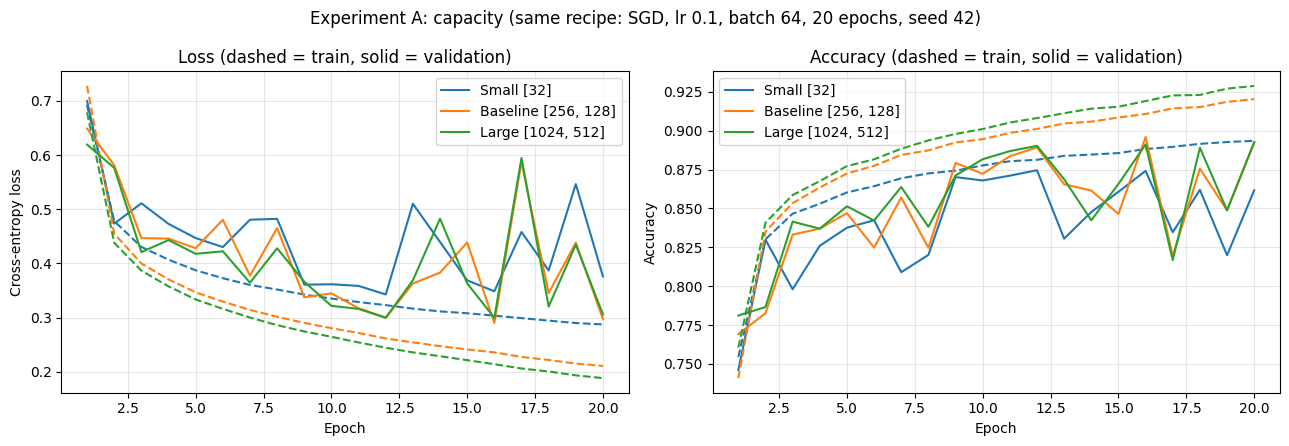

Model      Hidden           Params  Best val  Epoch  Final train loss  Time (s)
small      [32]             25,450    0.8746     12            0.2874       162
baseline   [256, 128]      235,146    0.8960     16            0.2108       188
large      [1024, 512]   1,333,770    0.8928     20            0.1883       370


In [50]:
plot_curves({"Small [32]": small_hist,
             "Baseline [256, 128]": baseline_hist,
             "Large [1024, 512]": large_hist},
            "Experiment A: capacity (same recipe: SGD, lr 0.1, batch 64, 20 epochs, seed 42)")

print(f"{'Model':<10} {'Hidden':<12} {'Params':>10} {'Best val':>9} {'Epoch':>6} "
      f"{'Final train loss':>17} {'Time (s)':>9}")
for s in [small_summary, baseline_summary, large_summary]:
    print(f"{s['name']:<10} {str(s['hidden']):<12} {s['params']:>10,} {s['best_val_acc']:>9.4f} "
          f"{s['best_epoch']:>6} {s['final_train_loss']:>17.4f} {s['time_s']:>9.0f}")

In [51]:
lr001_model, lr001_hist, lr001_summary = train_model(BASELINE_HIDDEN, lr=0.01, epochs=20, name="lr_0.01")

lr_0.01 | epoch  1: train loss 1.5260 acc 0.5285 | val loss 0.9050 acc 0.6806
lr_0.01 | epoch  2: train loss 0.7801 acc 0.7082 | val loss 0.6896 acc 0.7519
lr_0.01 | epoch  3: train loss 0.6468 acc 0.7727 | val loss 0.6054 acc 0.7836
lr_0.01 | epoch  4: train loss 0.5749 acc 0.8014 | val loss 0.5437 acc 0.8061
lr_0.01 | epoch  5: train loss 0.5313 acc 0.8161 | val loss 0.5016 acc 0.8231
lr_0.01 | epoch  6: train loss 0.5026 acc 0.8244 | val loss 0.5045 acc 0.8191
lr_0.01 | epoch  7: train loss 0.4822 acc 0.8321 | val loss 0.4938 acc 0.8238
lr_0.01 | epoch  8: train loss 0.4680 acc 0.8362 | val loss 0.4835 acc 0.8241
lr_0.01 | epoch  9: train loss 0.4546 acc 0.8410 | val loss 0.4264 acc 0.8523
lr_0.01 | epoch 10: train loss 0.4444 acc 0.8442 | val loss 0.4240 acc 0.8516
lr_0.01 | epoch 11: train loss 0.4364 acc 0.8476 | val loss 0.4129 acc 0.8579
lr_0.01 | epoch 12: train loss 0.4278 acc 0.8511 | val loss 0.4178 acc 0.8525
lr_0.01 | epoch 13: train loss 0.4198 acc 0.8536 | val loss 0.44

In [52]:
lr05_model, lr05_hist, lr05_summary = train_model(BASELINE_HIDDEN, lr=0.5, epochs=20, name="lr_0.5")

lr_0.5 | epoch  1: train loss 0.7482 acc 0.7157 | val loss 0.6735 acc 0.7709
lr_0.5 | epoch  2: train loss 0.4643 acc 0.8261 | val loss 0.6379 acc 0.7693
lr_0.5 | epoch  3: train loss 0.4053 acc 0.8507 | val loss 0.4305 acc 0.8498
lr_0.5 | epoch  4: train loss 0.3722 acc 0.8612 | val loss 0.5751 acc 0.7833
lr_0.5 | epoch  5: train loss 0.3507 acc 0.8690 | val loss 0.3835 acc 0.8651
lr_0.5 | epoch  6: train loss 0.3339 acc 0.8744 | val loss 0.5579 acc 0.8094
lr_0.5 | epoch  7: train loss 0.3200 acc 0.8796 | val loss 0.3649 acc 0.8739
lr_0.5 | epoch  8: train loss 0.3109 acc 0.8843 | val loss 0.5030 acc 0.8289
lr_0.5 | epoch  9: train loss 0.3011 acc 0.8864 | val loss 0.5858 acc 0.7926
lr_0.5 | epoch 10: train loss 0.2898 acc 0.8915 | val loss 0.3642 acc 0.8692
lr_0.5 | epoch 11: train loss 0.2828 acc 0.8945 | val loss 0.3538 acc 0.8741
lr_0.5 | epoch 12: train loss 0.2741 acc 0.8963 | val loss 0.3365 acc 0.8797
lr_0.5 | epoch 13: train loss 0.2670 acc 0.8992 | val loss 0.4131 acc 0.8687

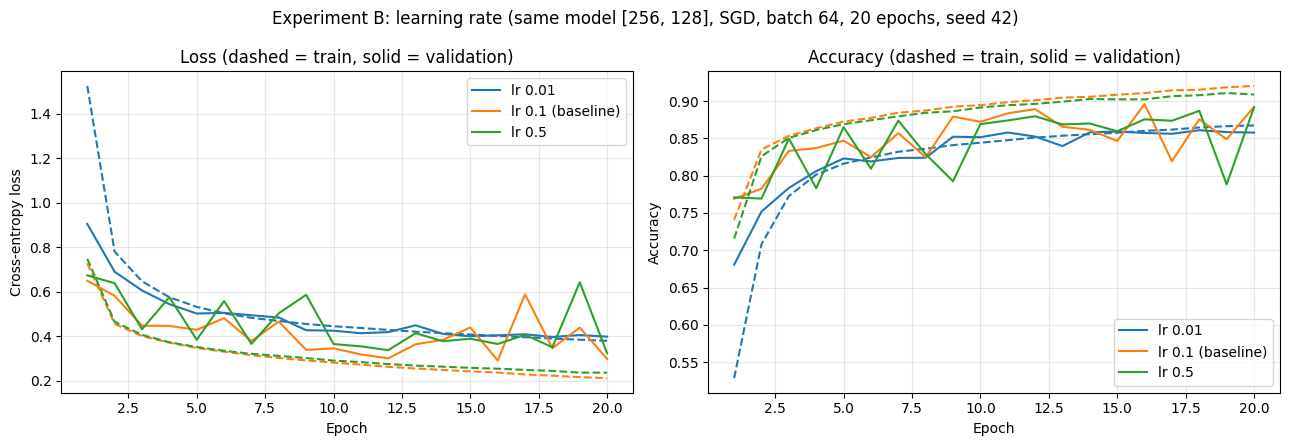

Run           lr  Best val  Epoch  Final train loss  Time (s)
lr_0.01     0.01    0.8610     18            0.3786       197
baseline     0.1    0.8960     16            0.2108       188
lr_0.5       0.5    0.8915     20            0.2354       193


In [53]:
plot_curves({"lr 0.01": lr001_hist,
             "lr 0.1 (baseline)": baseline_hist,
             "lr 0.5": lr05_hist},
            "Experiment B: learning rate (same model [256, 128], SGD, batch 64, 20 epochs, seed 42)")

print(f"{'Run':<10} {'lr':>5} {'Best val':>9} {'Epoch':>6} {'Final train loss':>17} {'Time (s)':>9}")
for s in [lr001_summary, baseline_summary, lr05_summary]:
    print(f"{s['name']:<10} {s['lr']:>5} {s['best_val_acc']:>9.4f} {s['best_epoch']:>6} "
          f"{s['final_train_loss']:>17.4f} {s['time_s']:>9.0f}")

In [54]:
print(f"{'Run':<18} {'Best val':>9} {'Mean val (ep 11-20)':>20} {'Std':>7}")
for label, h, s in [("lr 0.01", lr001_hist, lr001_summary),
                    ("lr 0.1 (baseline)", baseline_hist, baseline_summary),
                    ("lr 0.5", lr05_hist, lr05_summary)]:
    last10 = np.array(h["val_acc"][-10:])
    print(f"{label:<18} {s['best_val_acc']:>9.4f} {last10.mean():>20.4f} {last10.std(ddof=1):>7.4f}")

Run                 Best val  Mean val (ep 11-20)     Std
lr 0.01               0.8610               0.8558  0.0061
lr 0.1 (baseline)     0.8960               0.8679  0.0244
lr 0.5                0.8915               0.8668  0.0290


In [57]:
# Fixed stratified 10,000-image subset of the 50,000 training images (CPU-friendly option in the brief)
reg_train_indices, _ = train_test_split(
    train_indices,                         # positions in the original 60,000 images
    train_size=10000,
    stratify=all_labels[train_indices],
    random_state=SEED,
)
np.save("splits/reg_train_indices.npy", np.array(reg_train_indices))


def to_tensors(indices):
    """Images as a [N, 1, 28, 28] float tensor in 0-1 (the same values ToTensor() gives), plus labels."""
    X = train_data.data[indices].float().div(255.0).unsqueeze(1)
    y = train_data.targets[indices]
    return X, y


X_reg_train, y_reg_train = to_tensors(reg_train_indices)
X_reg_val, y_reg_val = to_tensors(val_indices)

reg_train_set = TensorDataset(X_reg_train, y_reg_train)
reg_val_set = TensorDataset(X_reg_val, y_reg_val)

g_reg = torch.Generator()   # seeded separately for every run
reg_train_loader = DataLoader(reg_train_set, batch_size=64, shuffle=True, generator=g_reg)
reg_train_eval_loader = DataLoader(reg_train_set, batch_size=1000, shuffle=False)   # clean pass over training data
reg_val_loader = DataLoader(reg_val_set, batch_size=1000, shuffle=False)

print("Training subset:", len(reg_train_set), " per class:", torch.bincount(y_reg_train).tolist())
print("Validation set: ", len(reg_val_set))
print("Overlap with validation:", len(set(reg_train_indices) & set(val_indices)))
print("Same pixel values as ToTensor():", torch.equal(X_reg_train[0], train_data[reg_train_indices[0]][0]))

Training subset: 10000  per class: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Validation set:  10000
Overlap with validation: 0
Same pixel values as ToTensor(): True


In [58]:
class RegMLP(nn.Module):
    """The baseline MLP, with optional dropout after each hidden layer."""

    def __init__(self, hidden_sizes, dropout=0.0):
        super().__init__()
        layers = []
        in_size = 784
        for h in hidden_sizes:
            layers.append(nn.Linear(in_size, h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))   # randomly zeroes this fraction of units during training
            in_size = h
        layers.append(nn.Linear(in_size, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.view(x.size(0), -1))


def train_one_epoch_reg(model, loader, lr, weight_decay=0.0):
    """One epoch of plain SGD, with L2 weight decay written into the update."""
    model.train()                                    # dropout ON
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        logits = model(images)
        loss = loss_fn(logits, labels)               # data loss only; the penalty is applied in the update

        model.zero_grad()
        loss.backward()

        with torch.no_grad():
            for p in model.parameters():
                if p.dim() > 1:                      # weight matrices: add the L2 penalty's gradient
                    p -= lr * (p.grad + weight_decay * p)
                else:                                # biases: no decay
                    p -= lr * p.grad


def train_reg(name, dropout=0.0, weight_decay=0.0, seed=SEED, epochs=60, lr=0.1):
    """Train the baseline architecture on the 10k subset; measure clean train and validation each epoch."""
    torch.manual_seed(seed)                          # initial weights AND dropout masks
    _ = g_reg.manual_seed(seed)                      # training batch order
    model = RegMLP(BASELINE_HIDDEN, dropout).to(device)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_one_epoch_reg(model, reg_train_loader, lr, weight_decay)

        # Clean pass: dropout off, cross-entropy only, so train and validation losses are comparable
        train_loss, train_acc = evaluate(model, reg_train_eval_loader)
        val_loss, val_acc = evaluate(model, reg_val_loader)

        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)

        if val_acc > best_val_acc:                   # checkpoint rule (as in Part 2)
            best_val_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())

        if epoch % 10 == 0:
            print(f"{name} | epoch {epoch:>2}: train loss {train_loss:.4f} acc {train_acc:.4f} | "
                  f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    elapsed = time.time() - start
    torch.save(best_state, f"checkpoints/{name}.pt")
    model.load_state_dict(best_state)

    summary = {"name": name, "dropout": dropout, "weight_decay": weight_decay, "seed": seed,
               "best_epoch": best_epoch, "best_val_acc": best_val_acc,
               "final_train_acc": history["train_acc"][-1], "final_val_acc": history["val_acc"][-1],
               "final_gap": history["train_acc"][-1] - history["val_acc"][-1],
               "min_val_loss": min(history["val_loss"]), "final_val_loss": history["val_loss"][-1],
               "time_s": elapsed}
    print(f"{name}: best val {best_val_acc:.4f} (epoch {best_epoch}) | final train {summary['final_train_acc']:.4f} "
          f"val {summary['final_val_acc']:.4f} gap {summary['final_gap']:.4f} | {elapsed:.0f} s\n")
    return model, history, summary

In [59]:
explore_configs = [
    # name,          dropout, weight decay
    ("none",         0.0,     0.0),
    ("dropout_0.2",  0.2,     0.0),
    ("dropout_0.5",  0.5,     0.0),
    ("wd_1e-4",      0.0,     1e-4),
    ("wd_1e-3",      0.0,     1e-3),
]

explore = {}   # name -> (history, summary)
for name, dropout, wd in explore_configs:
    _, hist, summ = train_reg(f"{name}_s{SEED}", dropout=dropout, weight_decay=wd, seed=SEED)
    explore[name] = (hist, summ)

none_s42 | epoch 10: train loss 0.7896 acc 0.7397 | val loss 0.8224 acc 0.7278
none_s42 | epoch 20: train loss 0.3474 acc 0.8675 | val loss 0.4477 acc 0.8375
none_s42 | epoch 30: train loss 0.3233 acc 0.8759 | val loss 0.4980 acc 0.8300
none_s42 | epoch 40: train loss 0.1615 acc 0.9382 | val loss 0.3976 acc 0.8672
none_s42 | epoch 50: train loss 0.2723 acc 0.9080 | val loss 0.5688 acc 0.8304
none_s42 | epoch 60: train loss 0.0943 acc 0.9664 | val loss 0.4453 acc 0.8727
none_s42: best val 0.8727 (epoch 60) | final train 0.9664 val 0.8727 gap 0.0937 | 67 s

dropout_0.2_s42 | epoch 10: train loss 0.6661 acc 0.7591 | val loss 0.6923 acc 0.7505
dropout_0.2_s42 | epoch 20: train loss 0.3968 acc 0.8496 | val loss 0.4789 acc 0.8254
dropout_0.2_s42 | epoch 30: train loss 0.3701 acc 0.8606 | val loss 0.5124 acc 0.8226
dropout_0.2_s42 | epoch 40: train loss 0.1786 acc 0.9303 | val loss 0.3674 acc 0.8774
dropout_0.2_s42 | epoch 50: train loss 0.1876 acc 0.9307 | val loss 0.3967 acc 0.8686
dropout_

Config        Best val  Ep  Final train  Final val  Final gap  Min val loss  Final val loss
none            0.8727  60       0.9664     0.8727     0.0937        0.3685          0.4453
dropout_0.2     0.8789  48       0.9515     0.8758     0.0757        0.3543          0.3967
dropout_0.5     0.8763  57       0.9154     0.8710     0.0444        0.3570          0.3706
wd_1e-4         0.8758  48       0.9669     0.8731     0.0938        0.3704          0.4196
wd_1e-3         0.8716  48       0.9417     0.8698     0.0719        0.3596          0.3831


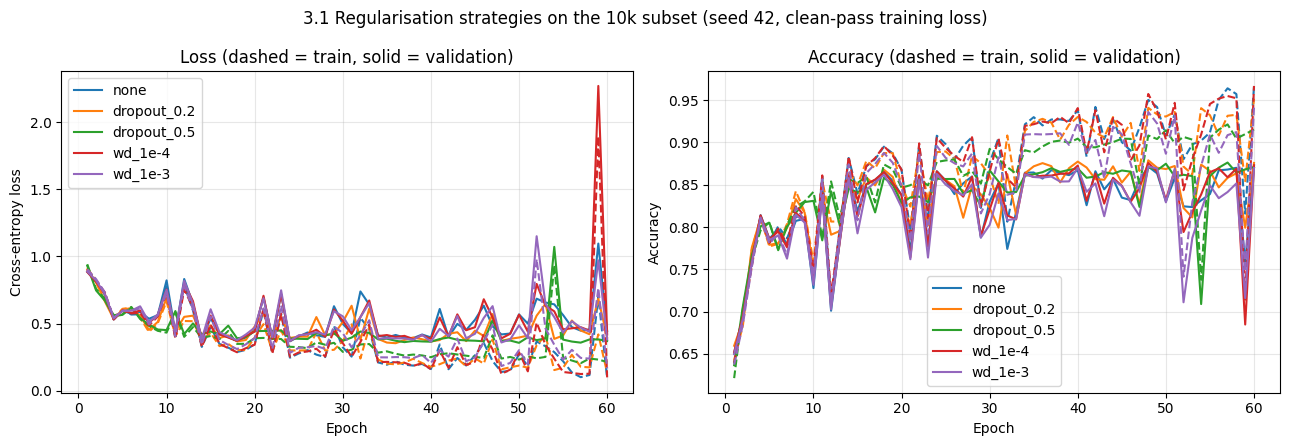

In [60]:
print(f"{'Config':<12} {'Best val':>9} {'Ep':>3} {'Final train':>12} {'Final val':>10} {'Final gap':>10} "
      f"{'Min val loss':>13} {'Final val loss':>15}")
for name, (h, s) in explore.items():
    print(f"{name:<12} {s['best_val_acc']:>9.4f} {s['best_epoch']:>3} {s['final_train_acc']:>12.4f} "
          f"{s['final_val_acc']:>10.4f} {s['final_gap']:>10.4f} {s['min_val_loss']:>13.4f} {s['final_val_loss']:>15.4f}")

plot_curves({name: h for name, (h, s) in explore.items()},
            "3.1 Regularisation strategies on the 10k subset (seed 42, clean-pass training loss)")

In [61]:
SEEDS = [42, 43, 44]
main_configs = {"none": (0.0, 0.0), "dropout_0.2": (0.2, 0.0)}   # name -> (dropout, weight decay)

seed_runs = {name: {SEED: explore[name]} for name in main_configs}   # reuse the seed-42 runs

for name, (dropout, wd) in main_configs.items():
    for seed in SEEDS:
        if seed in seed_runs[name]:
            continue                                  # seed 42 already trained in the exploration
        _, hist, summ = train_reg(f"{name}_s{seed}", dropout=dropout, weight_decay=wd, seed=seed)
        seed_runs[name][seed] = (hist, summ)

none_s43 | epoch 10: train loss 0.4231 acc 0.8509 | val loss 0.4580 acc 0.8371
none_s43 | epoch 20: train loss 0.2896 acc 0.8906 | val loss 0.3944 acc 0.8571
none_s43 | epoch 30: train loss 0.1994 acc 0.9270 | val loss 0.3691 acc 0.8696
none_s43 | epoch 40: train loss 0.1623 acc 0.9398 | val loss 0.3954 acc 0.8708
none_s43 | epoch 50: train loss 0.2400 acc 0.9034 | val loss 0.5499 acc 0.8305
none_s43 | epoch 60: train loss 0.1311 acc 0.9492 | val loss 0.4638 acc 0.8655
none_s43: best val 0.8737 (epoch 39) | final train 0.9492 val 0.8655 gap 0.0837 | 79 s

none_s44 | epoch 10: train loss 0.3655 acc 0.8670 | val loss 0.4043 acc 0.8520
none_s44 | epoch 20: train loss 0.3512 acc 0.8653 | val loss 0.4400 acc 0.8361
none_s44 | epoch 30: train loss 0.4110 acc 0.8586 | val loss 0.5663 acc 0.8249
none_s44 | epoch 40: train loss 0.2874 acc 0.8956 | val loss 0.5191 acc 0.8408
none_s44 | epoch 50: train loss 0.2647 acc 0.9087 | val loss 0.5458 acc 0.8336
none_s44 | epoch 60: train loss 0.1497 acc 

In [62]:
metrics = ["best_val_acc", "final_val_acc", "final_train_acc", "final_gap", "final_val_loss"]

for name in main_configs:
    print(f"\n{name}")
    print(f"{'Seed':<6}" + "".join(f"{m:>17}" for m in metrics))
    for seed in SEEDS:
        s = seed_runs[name][seed][1]
        print(f"{seed:<6}" + "".join(f"{s[m]:>17.4f}" for m in metrics))
    values = np.array([[seed_runs[name][seed][1][m] for m in metrics] for seed in SEEDS])
    print(f"{'Mean':<6}" + "".join(f"{v:>17.4f}" for v in values.mean(axis=0)))
    print(f"{'Std':<6}" + "".join(f"{v:>17.4f}" for v in values.std(axis=0, ddof=1)))


none
Seed       best_val_acc    final_val_acc  final_train_acc        final_gap   final_val_loss
42               0.8727           0.8727           0.9664           0.0937           0.4453
43               0.8737           0.8655           0.9492           0.0837           0.4638
44               0.8754           0.8531           0.9432           0.0901           0.5230
Mean             0.8739           0.8638           0.9529           0.0892           0.4774
Std              0.0014           0.0099           0.0120           0.0051           0.0406

dropout_0.2
Seed       best_val_acc    final_val_acc  final_train_acc        final_gap   final_val_loss
42               0.8789           0.8758           0.9515           0.0757           0.3967
43               0.8785           0.8746           0.9482           0.0736           0.4000
44               0.8778           0.7973           0.8513           0.0540           0.7613
Mean             0.8784           0.8492           0.9170    

In [63]:
def seed_summary(name, seed):
    h, s = seed_runs[name][seed]
    train_acc_10 = np.mean(h["train_acc"][-10:])
    val_acc_10 = np.mean(h["val_acc"][-10:])
    return {
        "best_val_acc": s["best_val_acc"],                      # checkpoint rule (includes early stopping)
        "val_acc_51_60": val_acc_10,                            # mean over last 10 epochs
        "gap_51_60": train_acc_10 - val_acc_10,                 # mean train-val gap, last 10 epochs
        "min_val_loss": s["min_val_loss"],
        "val_loss_51_60": np.mean(h["val_loss"][-10:]),
        "final_val_acc": s["final_val_acc"],                    # single snapshot at epoch 60
    }

for name in main_configs:
    rows = [seed_summary(name, seed) for seed in SEEDS]
    cols = list(rows[0].keys())
    print(f"\n{name}")
    print(f"{'Seed':<6}" + "".join(f"{c:>15}" for c in cols))
    for seed, r in zip(SEEDS, rows):
        print(f"{seed:<6}" + "".join(f"{r[c]:>15.4f}" for c in cols))
    values = np.array([[r[c] for c in cols] for r in rows])
    print(f"{'Mean':<6}" + "".join(f"{v:>15.4f}" for v in values.mean(axis=0)))
    print(f"{'Std':<6}" + "".join(f"{v:>15.4f}" for v in values.std(axis=0, ddof=1)))


none
Seed     best_val_acc  val_acc_51_60      gap_51_60   min_val_loss val_loss_51_60  final_val_acc
42             0.8727         0.8413         0.0767         0.3685         0.5971         0.8727
43             0.8737         0.8424         0.0790         0.3691         0.5550         0.8655
44             0.8754         0.8571         0.0818         0.3805         0.4996         0.8531
Mean           0.8739         0.8469         0.0792         0.3727         0.5506         0.8638
Std            0.0014         0.0088         0.0026         0.0068         0.0489         0.0099

dropout_0.2
Seed     best_val_acc  val_acc_51_60      gap_51_60   min_val_loss val_loss_51_60  final_val_acc
42             0.8789         0.8490         0.0631         0.3543         0.4892         0.8758
43             0.8785         0.8509         0.0651         0.3521         0.4869         0.8746
44             0.8778         0.8596         0.0643         0.3537         0.4504         0.7973
Mean       

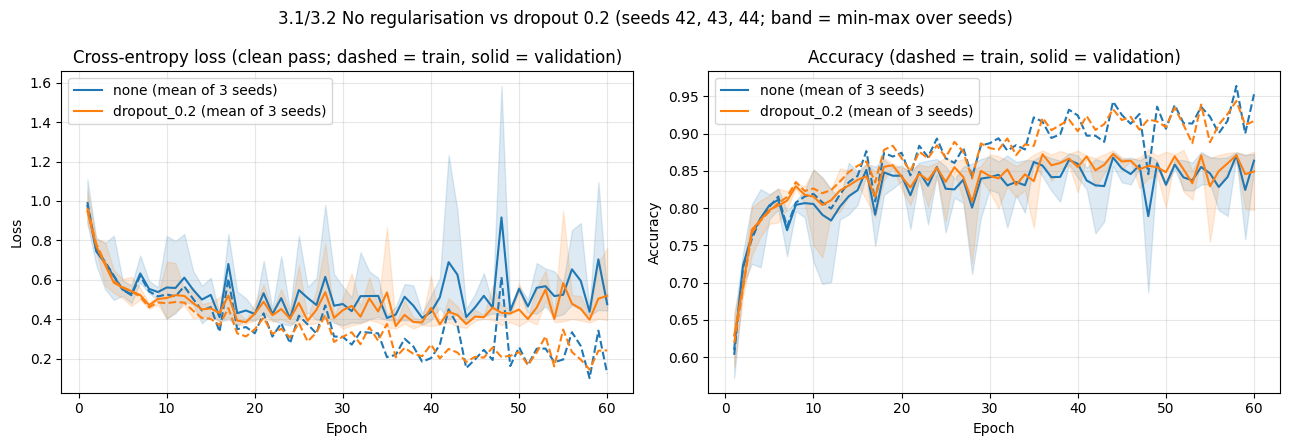

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs = np.arange(1, 61)

for name, colour in [("none", "tab:blue"), ("dropout_0.2", "tab:orange")]:
    for ax, key in [(axes[0], "loss"), (axes[1], "acc")]:
        train = np.array([seed_runs[name][s][0][f"train_{key}"] for s in SEEDS])   # shape (3 seeds, 60 epochs)
        val = np.array([seed_runs[name][s][0][f"val_{key}"] for s in SEEDS])

        ax.plot(epochs, train.mean(axis=0), linestyle="--", color=colour)
        ax.plot(epochs, val.mean(axis=0), color=colour, label=f"{name} (mean of 3 seeds)")
        ax.fill_between(epochs, val.min(axis=0), val.max(axis=0), color=colour, alpha=0.15)

axes[0].set_title("Cross-entropy loss (clean pass; dashed = train, solid = validation)")
axes[1].set_title("Accuracy (dashed = train, solid = validation)")
for ax, ylabel in zip(axes, ["Loss", "Accuracy"]):
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("3.1/3.2 No regularisation vs dropout 0.2 (seeds 42, 43, 44; band = min-max over seeds)")
plt.tight_layout()
plt.show()